# EDA na Prática — Online Shoppers Purchasing Intention (UCI)

Aplicação do roteiro da aula prática de EDA (Aulas 9, 10 e 11) ao dataset **Online Shoppers Purchasing Intention** do UCI Machine Learning Repository.

**Contexto do dataset:** cada linha é uma **sessão de navegação** em uma loja online (12.330 sessões, coletadas ao longo de um ano). As variáveis descrevem quantas páginas de cada tipo o visitante viu e quanto tempo passou nelas, métricas do Google Analytics (taxa de rejeição, taxa de saída, valor da página), dados técnicos (sistema operacional, navegador, região, origem do tráfego) e calendário (mês, fim de semana, proximidade de datas especiais). O alvo `Revenue` indica se a sessão **terminou em compra**. Fonte: Sakar, Polat, Katircioglu & Kastro (2019), *Real-time prediction of online shoppers' purchasing intention using multilayer perceptron and LSTM recurrent neural networks*, Neural Computing and Applications.

Seguimos o mesmo ciclo **iterativo** da aula: estrutura → estatística descritiva "antes" → tratamento de ausentes e outliers → estatística descritiva "depois" → análise relacional (bivariada e multivariada).

## Setup de Bibliotecas e Dados

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

COR_NEUTRA = "lightgray"     # convenção: cinza-claro pra tudo que é "pano de fundo" genérico
COR_CONTEXTO = "#e9d4d0"    # rosa-claro pra classe de referência ("Não comprou")
COR_DESTAQUE = "#2d223a"    # roxo pra classe de interesse ("Comprou")
COR_ALERTA = "tab:red"       # exceção deliberada: outliers/pontos de atenção

SEED = 42  # amostras reprodutíveis (testes e gráficos com muitos pontos)

# Funciona rodando o notebook a partir da raiz do projeto ou de notebooks/
RAIZ = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent

## Carregando o Dataset

Arquivo `online_shoppers_intention.csv`, baixado do UCI (`online+shoppers+purchasing+intention+dataset.zip`) e salvo em `data/raw/`.

In [2]:
# Online Shoppers Purchasing Intention (UCI Machine Learning Repository, id=468)
df = pd.read_csv(RAIZ / "data" / "raw" / "online_shoppers_intention.csv")
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


### Renomeando as variáveis

Os nomes originais (em inglês, no padrão do Google Analytics) são pouco claros: `ProductRelated` é o número de **páginas** de produto, `ProductRelated_Duration` é o **tempo**, em segundos, e `SpecialDay` é a **proximidade** de uma data comemorativa. Para facilitar a leitura de todo o notebook (e do dashboard), renomeamos tudo para português, deixando a unidade explícita no nome quando houver. Os valores de `Month` e `VisitorType` também são traduzidos.

| Nome original | Novo nome | O que significa |
|---|---|---|
| `Administrative` | `paginas_administrativas` | Nº de páginas administrativas vistas (conta, login, contato) |
| `Administrative_Duration` | `tempo_administrativas_seg` | Tempo total nessas páginas (segundos) |
| `Informational` | `paginas_informativas` | Nº de páginas informativas vistas (sobre a loja, políticas, FAQ) |
| `Informational_Duration` | `tempo_informativas_seg` | Tempo total nessas páginas (segundos) |
| `ProductRelated` | `paginas_produto` | Nº de páginas de produto vistas |
| `ProductRelated_Duration` | `tempo_produto_seg` | Tempo total em páginas de produto (segundos) |
| `BounceRates` | `taxa_rejeicao` | Taxa de rejeição média das páginas visitadas (*bounce rate* do GA) |
| `ExitRates` | `taxa_saida` | Taxa de saída média das páginas visitadas (*exit rate* do GA) |
| `PageValues` | `valor_pagina` | Valor médio das páginas visitadas antes de uma compra (*page value* do GA) |
| `SpecialDay` | `proximidade_data_especial` | Proximidade de uma data comemorativa (0 = longe, 1 = no dia) |
| `Month` | `mes` | Mês da sessão (Jan, Fev, ..., Dez) |
| `OperatingSystems` | `sistema_operacional` | Código do sistema operacional |
| `Browser` | `navegador` | Código do navegador |
| `Region` | `regiao` | Código da região do visitante |
| `TrafficType` | `origem_trafego` | Código da origem do tráfego (anúncio, busca, link direto...) |
| `VisitorType` | `tipo_visitante` | Novo, Recorrente ou Outro |
| `Weekend` | `fim_de_semana` | A sessão foi num fim de semana? |
| `Revenue` | `comprou` | A sessão terminou em compra? (criada mais abaixo) |

In [3]:
NOVOS_NOMES = {
    "Administrative": "paginas_administrativas",
    "Administrative_Duration": "tempo_administrativas_seg",
    "Informational": "paginas_informativas",
    "Informational_Duration": "tempo_informativas_seg",
    "ProductRelated": "paginas_produto",
    "ProductRelated_Duration": "tempo_produto_seg",
    "BounceRates": "taxa_rejeicao",
    "ExitRates": "taxa_saida",
    "PageValues": "valor_pagina",
    "SpecialDay": "proximidade_data_especial",
    "Month": "mes",
    "OperatingSystems": "sistema_operacional",
    "Browser": "navegador",
    "Region": "regiao",
    "TrafficType": "origem_trafego",
    "VisitorType": "tipo_visitante",
    "Weekend": "fim_de_semana",
}
df = df.rename(columns=NOVOS_NOMES)

df["mes"] = df["mes"].replace({"Feb": "Fev", "Apr": "Abr", "May": "Mai", "June": "Jun",
                               "Aug": "Ago", "Sep": "Set", "Oct": "Out", "Dec": "Dez"})
df["tipo_visitante"] = df["tipo_visitante"].replace({"Returning_Visitor": "Recorrente",
                                                     "New_Visitor": "Novo", "Other": "Outro"})
df.head()

,paginas_administrativas,tempo_administrativas_seg,paginas_informativas,tempo_informativas_seg,paginas_produto,tempo_produto_seg,taxa_rejeicao,taxa_saida,valor_pagina,proximidade_data_especial,mes,sistema_operacional,navegador,regiao,origem_trafego,tipo_visitante,fim_de_semana,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Fev,1,1,1,1,Recorrente,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Fev,2,2,1,2,Recorrente,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Fev,4,1,9,3,Recorrente,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Fev,3,2,2,4,Recorrente,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Fev,3,3,1,4,Recorrente,True,False


## 1. Princípio Estrutural

Antes de qualquer análise, precisamos entender a "anatomia" dos dados: quantas linhas e colunas temos, que tipo de dado cada coluna guarda, se há valores faltantes e se há duplicadas.

**Antes de rodar:** o dataset tem 17 variáveis preditoras e o alvo `Revenue`. Como é um log de sessões de **um ano** de uma única loja (e o próprio artigo filtrou as sessões para que cada uma pertencesse a um usuário diferente), esperamos **milhares** de linhas, mas não milhões.

| Grupo | Variáveis |
|---|---|
| Navegação | `paginas_administrativas`, `paginas_informativas`, `paginas_produto` (nº de páginas de cada tipo vistas na sessão) e os respectivos `tempo_*_seg` (tempo total, em segundos) |
| Google Analytics | `taxa_rejeicao` (taxa de rejeição média das páginas visitadas), `taxa_saida` (taxa de saída média), `valor_pagina` (valor médio das páginas visitadas antes de uma transação) |
| Calendário | `mes`, `fim_de_semana`, `proximidade_data_especial` (proximidade de uma data especial, de 0 a 1 — ex.: Dia dos Namorados, Dia das Mães) |
| Técnicas | `sistema_operacional`, `navegador`, `regiao`, `origem_trafego` (códigos numéricos, anonimizados), `tipo_visitante` (Novo, Recorrente ou Outro) |
| Alvo | `Revenue` — a sessão terminou em compra? |

### Dimensão e Tipos de Dados

In [4]:
df.shape

(12330, 18)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   paginas_administrativas    12330 non-null  int64  
 1   tempo_administrativas_seg  12330 non-null  float64
 2   paginas_informativas       12330 non-null  int64  
 3   tempo_informativas_seg     12330 non-null  float64
 4   paginas_produto            12330 non-null  int64  
 5   tempo_produto_seg          12330 non-null  float64
 6   taxa_rejeicao              12330 non-null  float64
 7   taxa_saida                 12330 non-null  float64
 8   valor_pagina               12330 non-null  float64
 9   proximidade_data_especial  12330 non-null  float64
 10  mes                        12330 non-null  object 
 11  sistema_operacional        12330 non-null  int64  
 12  navegador                  12330 non-null  int64  
 13  regiao                     12330 non-null  int

In [6]:
df.describe()

,paginas_administrativas,tempo_administrativas_seg,paginas_informativas,tempo_informativas_seg,paginas_produto,tempo_produto_seg,taxa_rejeicao,taxa_saida,valor_pagina,proximidade_data_especial,sistema_operacional,navegador,regiao,origem_trafego
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


**Observações estruturais:**
- 12.330 sessões e 18 colunas: 9 medidas quantitativas de navegação, 1 ordinal (`proximidade_data_especial`), 4 categóricas **codificadas como inteiros** (`sistema_operacional`, `navegador`, `regiao`, `origem_trafego`), 2 categóricas de texto (`mes`, `tipo_visitante`) e 2 booleanas (`fim_de_semana`, `Revenue`).
- Os códigos de SO, navegador, região e tráfego são **rótulos**, não quantidades: calcular média de `navegador` não tem significado. Vamos tratá-los como categorias.
- `taxa_rejeicao` e `taxa_saida` estão entre 0 e 0,2 — o máximo de **exatamente 0,2** em ambas sugere um teto do sistema de medição (veremos adiante).
- `df.info()` não mostra nulos.

### Duplicadas

In [7]:
df.duplicated().sum()

np.int64(125)

In [8]:
duplicadas = df[df.duplicated(keep=False)]
print(f"Linhas envolvidas em duplicatas: {len(duplicadas)}")
print("\nPáginas de produto vistas nessas sessões:")
print(duplicadas["paginas_produto"].value_counts())
print("\nTaxa de compra nessas sessões:", duplicadas["Revenue"].mean())
duplicadas.head()

Linhas envolvidas em duplicatas: 201

Páginas de produto vistas nessas sessões:
paginas_produto
1    189
2     12
Name: count, dtype: int64

Taxa de compra nessas sessões: 0.0


,paginas_administrativas,tempo_administrativas_seg,paginas_informativas,tempo_informativas_seg,paginas_produto,tempo_produto_seg,taxa_rejeicao,taxa_saida,valor_pagina,proximidade_data_especial,mes,sistema_operacional,navegador,regiao,origem_trafego,tipo_visitante,fim_de_semana,Revenue
85,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Fev,1,1,1,3,Recorrente,False,False
132,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Fev,3,2,3,3,Recorrente,False,False
158,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Fev,1,1,1,3,Recorrente,False,False
159,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Fev,3,2,3,3,Recorrente,False,False
178,0,0.0,0,0.0,1,0.0,0.2,0.2,0.0,0.0,Fev,3,2,3,3,Recorrente,False,False


Há 125 linhas idênticas a alguma outra. Olhando de perto, **todas** são sessões mínimas: 1 ou 2 páginas de produto, tempo 0, taxa de rejeição e de saída 0,2 e nenhuma compra. Como o dataset **não tem identificador de sessão** e as variáveis restantes (mês, SO, navegador, região, tráfego) têm poucos valores possíveis, é natural que visitantes diferentes que "entram e saem" gerem linhas idênticas. Não há evidência de que sejam registros repetidos por erro, então **mantemos** as duplicatas: removê-las subestimaria o volume real de sessões rápidas sem compra.

### Renomeando o atributo alvo para facilitar a interpretação

O alvo `Revenue` vem como booleano. Criamos a coluna `comprou` com rótulos em português, já na convenção de cor do notebook (rosa = "Não comprou", roxo = "Comprou"). Também trocamos `fim_de_semana` para "Sim"/"Não" e transformamos os códigos técnicos em texto, para que nenhum gráfico ou estatística os trate como números.

In [9]:
df["comprou"] = np.where(df["Revenue"], "Comprou", "Não comprou")
print(df["comprou"].value_counts())
df.drop(columns=["Revenue"], inplace=True)

df["fim_de_semana"] = np.where(df["fim_de_semana"], "Sim", "Não")
for col in ["sistema_operacional", "navegador", "regiao", "origem_trafego"]:
    df[col] = df[col].astype(str)

df.head()

comprou
Não comprou    10422
Comprou         1908
Name: count, dtype: int64


,paginas_administrativas,tempo_administrativas_seg,paginas_informativas,tempo_informativas_seg,paginas_produto,tempo_produto_seg,taxa_rejeicao,taxa_saida,valor_pagina,proximidade_data_especial,mes,sistema_operacional,navegador,regiao,origem_trafego,tipo_visitante,fim_de_semana,comprou
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Fev,1,1,1,1,Recorrente,Não,Não comprou
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Fev,2,2,1,2,Recorrente,Não,Não comprou
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Fev,4,1,9,3,Recorrente,Não,Não comprou
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Fev,3,2,2,4,Recorrente,Não,Não comprou
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Fev,3,3,1,4,Recorrente,Sim,Não comprou


## 2. Dados Faltantes

In [10]:
df.isna().sum()

paginas_administrativas      0
tempo_administrativas_seg    0
paginas_informativas         0
tempo_informativas_seg       0
paginas_produto              0
tempo_produto_seg            0
taxa_rejeicao                0
taxa_saida                   0
valor_pagina                 0
proximidade_data_especial    0
mes                          0
sistema_operacional          0
navegador                    0
regiao                       0
origem_trafego               0
tipo_visitante               0
fim_de_semana                0
comprou                      0
dtype: int64

**Discussão:** Alguma feature tem dados ausentes nos seus dados?

*Resposta*: pelo `isna()`, nenhuma. Mas "sem `NaN`" não é o mesmo que "sem ausência". Conhecendo como o Google Analytics mede o tempo, procuramos três formas de ausência disfarçada:

1. **Tempo zero com páginas visitadas.** O GA calcula o tempo numa página pela diferença até o próximo clique. A **última** página da sessão (e, portanto, sessões de uma página só) não tem tempo medido e fica com **0**. Esse 0 não significa "o visitante ficou 0 segundos", e sim "tempo não medido".
2. **Sessões sem nenhuma página.** Uma sessão sem páginas visitadas não deveria existir.
3. **Meses inteiros faltando.** O dataset diz cobrir um ano, mas precisamos checar se todos os 12 meses aparecem.

In [11]:
pares = {
    "paginas_administrativas": "tempo_administrativas_seg",
    "paginas_informativas": "tempo_informativas_seg",
    "paginas_produto": "tempo_produto_seg",
}

# 1. Tempo não medido: viu páginas daquele tipo, mas a duração ficou 0
tempo_nao_medido = pd.DataFrame({
    f"{pag}_tempo_ausente": (df[pag] > 0) & (df[dur] == 0) for pag, dur in pares.items()
})
print("1. Sessões com páginas vistas mas tempo = 0:")
print(tempo_nao_medido.sum())
print("   (e o contrário, tempo > 0 sem páginas:",
      sum(((df[pag] == 0) & (df[dur] > 0)).sum() for pag, dur in pares.items()), ")")

# 2. Sessões sem nenhuma página
total_paginas = df[list(pares)].sum(axis=1)
print(f"\n2. Sessões com 0 páginas no total: {(total_paginas == 0).sum()}")

# 3. Meses presentes
print("\n3. Meses presentes:", sorted(df["mes"].unique()))

1. Sessões com páginas vistas mas tempo = 0:
paginas_administrativas_tempo_ausente    135
paginas_informativas_tempo_ausente       226
paginas_produto_tempo_ausente            717
dtype: int64
   (e o contrário, tempo > 0 sem páginas: 0 )

2. Sessões com 0 páginas no total: 6

3. Meses presentes: ['Ago', 'Dez', 'Fev', 'Jul', 'Jun', 'Mai', 'Mar', 'Nov', 'Out', 'Set']


#### Identificando o mecanismo de dados ausentes

**Conhecimento de Domínio**

*Como os dados foram coletados:*
- As métricas vêm do **Google Analytics** de uma loja online. O artigo original explica que `taxa_rejeicao`, `taxa_saida` e `valor_pagina` são as métricas do GA para as páginas visitadas, e as durações são somas do tempo por página.

*Qual a natureza da fonte de dados:*
- Logs automáticos não "esquecem" de registrar um campo como um formulário preenchido à mão. Os ausentes aqui vêm do **método de medição** (o tempo da última página nunca é medido) ou do **recorte da coleta** (meses que ficaram de fora).

**As ausências ocorrem juntas?**

Temos três indicadores de "tempo não medido", um por tipo de página, todos com centenas de casos. Com esse volume, a nota da aula vale: a correlação entre os indicadores de ausência passa a fazer sentido, além da contagem bruta.

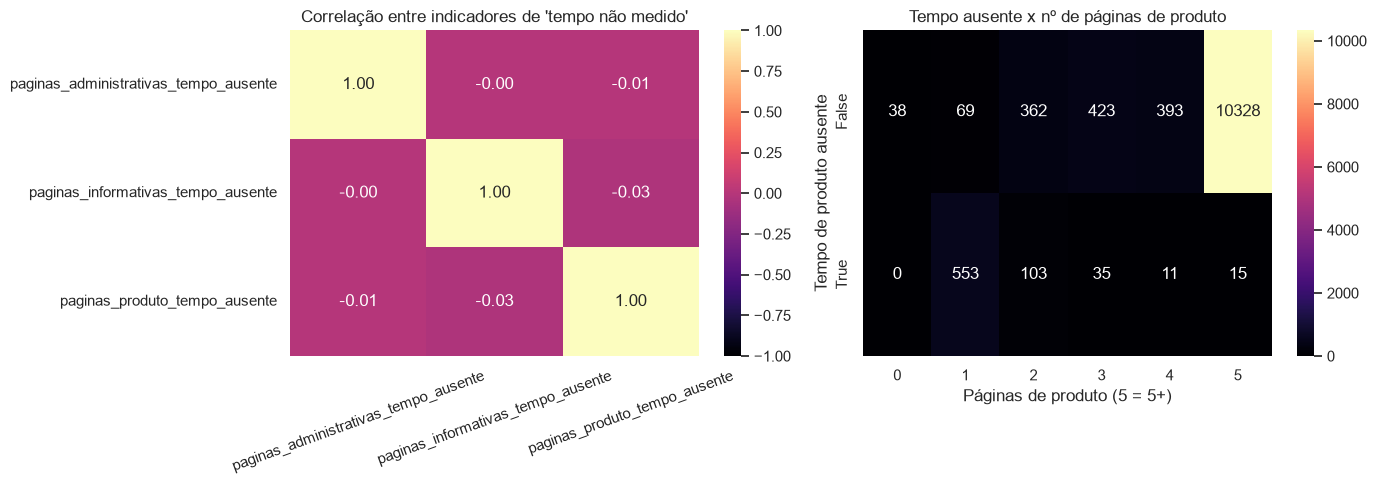

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(tempo_nao_medido.astype(int).corr(), annot=True, fmt=".2f",
            cmap="magma", vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlação entre indicadores de 'tempo não medido'")
axes[0].tick_params(axis="x", rotation=20)

tabela_contingencia = pd.crosstab(tempo_nao_medido["paginas_produto_tempo_ausente"], df["paginas_produto"].clip(upper=5),
                                  rownames=["Tempo de produto ausente"], colnames=["Páginas de produto (5 = 5+)"])
sns.heatmap(tabela_contingencia, annot=True, fmt="d", cmap="magma", ax=axes[1])
axes[1].set_title("Tempo ausente x nº de páginas de produto")

plt.tight_layout()
plt.show()

In [13]:
# O tempo ausente está associado à taxa de rejeição e à compra?
ausente_prod = tempo_nao_medido["paginas_produto_tempo_ausente"]
pd.DataFrame({
    "n_sessoes": df.groupby(ausente_prod).size(),
    "bounce_mediano": df.groupby(ausente_prod)["taxa_rejeicao"].median(),
    "taxa_compra": df.groupby(ausente_prod)["comprou"].apply(lambda s: (s == "Comprou").mean()),
}).rename(index={False: "tempo medido", True: "tempo ausente"}).round(3)

,n_sessoes,bounce_mediano,taxa_compra
paginas_produto_tempo_ausente,,,
tempo medido,11613,0.002,0.164
tempo ausente,717,0.200,0.010


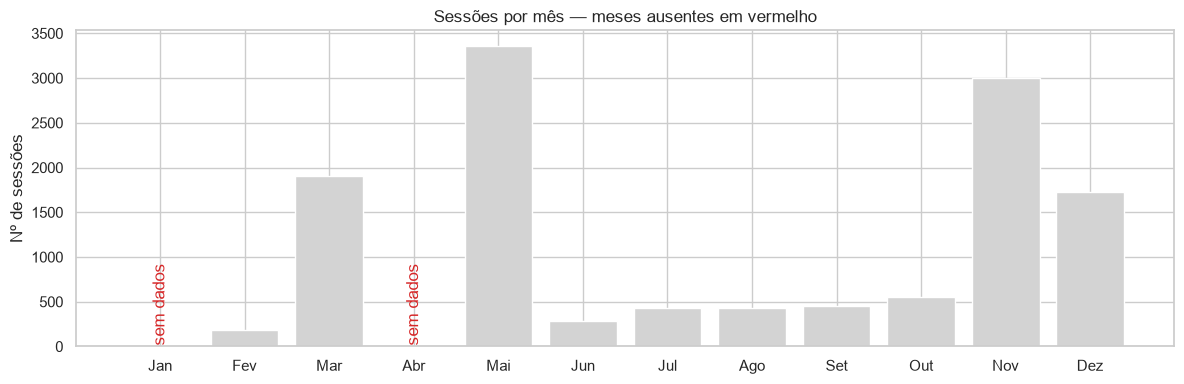

In [14]:
ordem_meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(12, 4))
contagem_mes = df["mes"].value_counts().reindex(ordem_meses, fill_value=0)
cores = [COR_ALERTA if n == 0 else COR_NEUTRA for n in contagem_mes]
ax.bar(contagem_mes.index, contagem_mes.values, color=cores)
for i, n in enumerate(contagem_mes):
    if n == 0:
        ax.annotate("sem dados", (i, 50), ha="center", color=COR_ALERTA, rotation=90)
ax.set_title("Sessões por mês — meses ausentes em vermelho")
ax.set_ylabel("Nº de sessões")
plt.tight_layout()
plt.show()

**Pra discutir:** quantas linhas têm as ausências juntas? Isso muda a hipótese sobre o mecanismo (MCAR/MAR/MNAR)?

*Relembrando:*
- MCAR: Mecanismo Aleatório e sem viés
- MAR: Mecanismo Randômico e com viés possível de corrigir
- MNAR: Mecanismo Não Randômico relacionada à própria feature

*Resposta:*

- **Tempo não medido → MNAR (por construção do instrumento).** Os indicadores dos três tipos de página têm correlação positiva entre si, e o tempo de produto ausente se concentra nas sessões de **1 página** (a grande maioria dos 717 casos). A ausência depende do **próprio comportamento** que a variável mede: quem sai logo não tem o tempo registrado. Essas sessões têm taxa de rejeição mediana de 0,2 (o teto) e taxa de compra perto de **1%**, contra ~16% nas demais. Removê-las apagaria justamente o perfil "entrou e saiu" e inflaria a taxa de conversão.
- **Sessões com 0 páginas (6 casos) → erro de dados.** Não é possível ter uma sessão sem nenhuma página vista. Volume desprezível.
- **Janeiro e abril ausentes → ausência no recorte da coleta.** Não há como recuperar esses meses. Isso não distorce cada sessão individualmente, mas limita qualquer conclusão **sazonal**: não sabemos como a loja se comporta no pós-Natal (janeiro) nem em abril.

## 3. Princípio Distribucional

Ainda com os dados originais (sem tratar ausentes ou outliers), calculamos as estatísticas descritivas e olhamos as distribuições. Esse retrato "antes" orienta as decisões de tratamento.

**Escolha das variáveis:**
- Quantitativas: as 9 medidas de navegação (`VARS_QUANT`). Para os gráficos com muitos painéis e para o dashboard, usamos um subconjunto de 5 variáveis centrais (`VARS_CORE`): produto (páginas e tempo), rejeição, saída e valor da página.
- Qualitativas: `mes`, `tipo_visitante`, `fim_de_semana`, `proximidade_data_especial` (ordinal com 6 níveis), `sistema_operacional`, `navegador`, `regiao`, `origem_trafego`.

In [15]:
VARS_QUANT = ["paginas_administrativas", "tempo_administrativas_seg", "paginas_informativas", "tempo_informativas_seg",
              "paginas_produto", "tempo_produto_seg", "taxa_rejeicao", "taxa_saida", "valor_pagina"]
VARS_CORE = ["paginas_produto", "tempo_produto_seg", "taxa_rejeicao", "taxa_saida", "valor_pagina"]
VARS_QUALI = ["mes", "tipo_visitante", "fim_de_semana", "proximidade_data_especial", "sistema_operacional", "navegador", "regiao", "origem_trafego"]

### Tabela descritiva, com assimetria e curtose

desc = df[VARS_QUANT].describe().T
desc["skewness"] = df[VARS_QUANT].skew()
desc["kurtosis"] = df[VARS_QUANT].kurtosis()
desc["pct_zeros"] = (df[VARS_QUANT] == 0).mean() * 100

(
    desc[["mean", "50%", "std", "min", "max", "skewness", "kurtosis", "pct_zeros"]]
    .rename(columns={"50%": "median"})
    .round(3)
    .style.format(precision=3)
    .background_gradient(cmap="magma", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis,pct_zeros
paginas_administrativas,2.315,1.000,3.322,0.000,27.000,1.960,4.701,46.780
tempo_administrativas_seg,80.819,7.500,176.779,0.000,3398.750,5.616,50.557,47.875
paginas_informativas,0.504,0.000,1.270,0.000,24.000,4.036,26.932,78.662
tempo_informativas_seg,34.472,0.000,140.749,0.000,2549.375,7.579,76.317,80.495
paginas_produto,31.731,18.000,44.476,0.000,705.000,4.342,31.212,0.308
tempo_produto_seg,1194.746,598.937,1913.669,0.000,63973.522,7.263,137.174,6.123
taxa_rejeicao,0.022,0.003,0.048,0.000,0.200,2.948,7.723,44.753
taxa_saida,0.043,0.025,0.049,0.000,0.200,2.149,4.017,0.616
valor_pagina,5.889,0.000,18.568,0.000,361.764,6.383,65.636,77.859


**Pra discutir:** quais variáveis já parecem assimétricas (`skewness` acima de 1) ou com cauda pesada (`kurtosis` maior que 2 em módulo)?

*Resposta*: **todas as nove**. A menos assimétrica é `paginas_administrativas` (skew ≈ 2), e as mais extremas são as durações: `tempo_produto_seg` (skew ≈ 7, kurtosis ≈ 137) e `tempo_informativas_seg` (skew ≈ 7,6). A coluna `pct_zeros` explica boa parte disso: **~78% das sessões têm `valor_pagina` = 0**, ~79% não viram nenhuma página informativa e quase metade não viu páginas administrativas. São distribuições de "muitos zeros + cauda longa", típicas de comportamento na web: a maioria das visitas é curta e poucas são muito longas. Em todas, a **média fica bem acima da mediana**.

### Distribuições de dados

Onde fizer sentido, comparamos "Não comprou" (rosa) vs. "Comprou" (roxo).

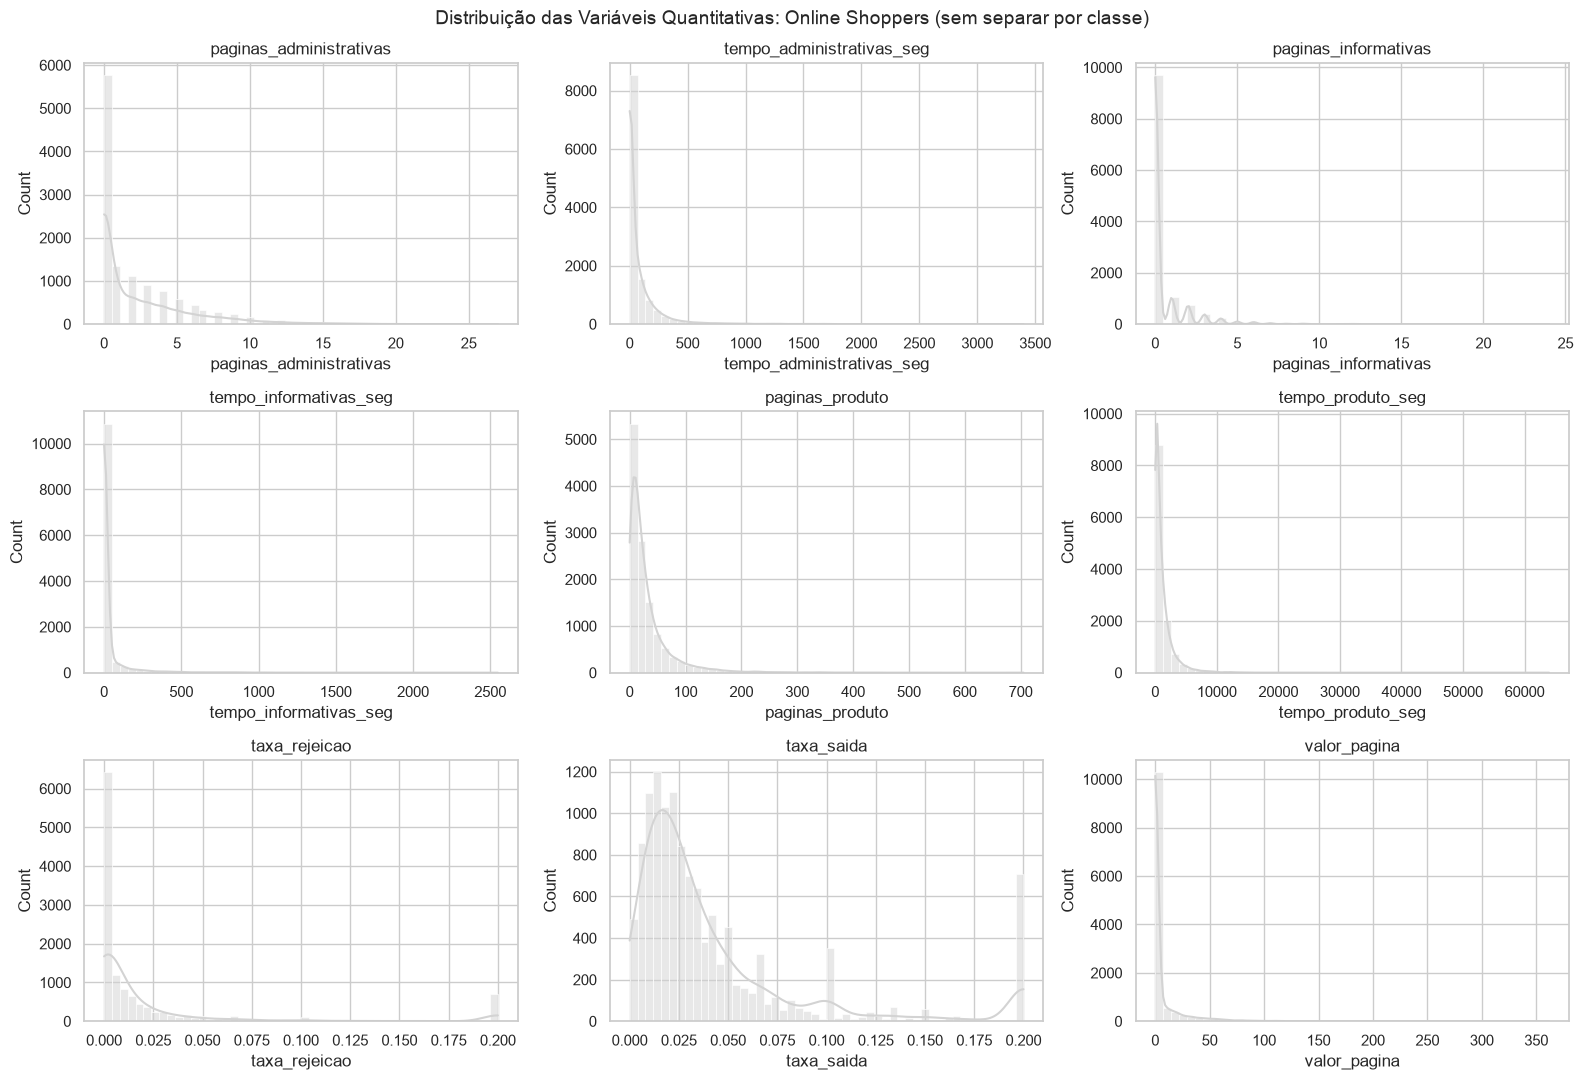

In [16]:
fig, axes = plt.subplots(3, 3, figsize=(16, 11))
axes = axes.ravel()

for i, col in enumerate(VARS_QUANT):
    sns.histplot(data=df, x=col, bins=50, kde=True, color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)

fig.suptitle("Distribuição das Variáveis Quantitativas: Online Shoppers (sem separar por classe)", fontsize=14)
plt.tight_layout()
plt.show()

As caudas longas espremem quase tudo nas primeiras barras. Para ver o formato da massa principal por classe, cortamos no **percentil 99** (só na visualização, nenhum dado é removido) e usamos `stat="density"`, porque as classes têm tamanhos muito diferentes.

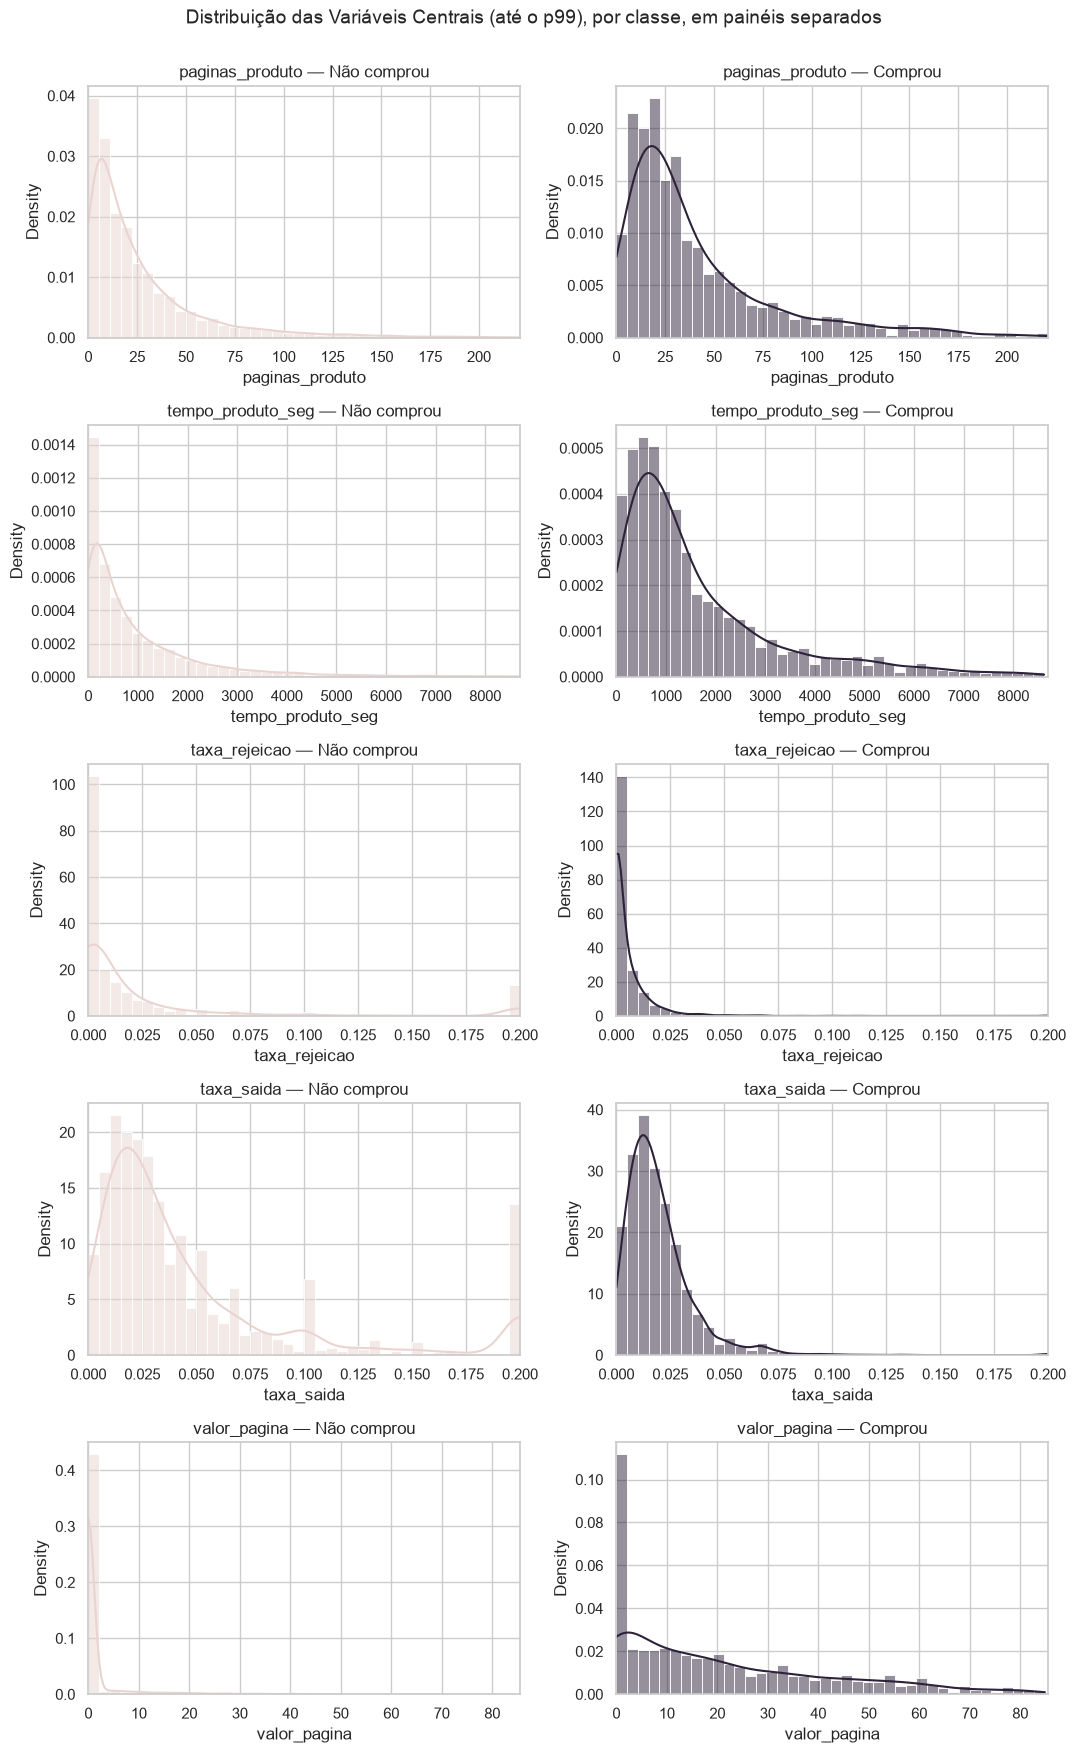

In [17]:
fig, axes = plt.subplots(len(VARS_CORE), 2, figsize=(11, 3.5 * len(VARS_CORE)))

for i, col in enumerate(VARS_CORE):
    lim = (df[col].min(), df[col].quantile(0.99))
    for j, (classe, cor) in enumerate([("Não comprou", COR_CONTEXTO), ("Comprou", COR_DESTAQUE)]):
        subset = df[(df["comprou"] == classe) & df[col].between(*lim)]
        sns.histplot(data=subset, x=col, bins=40, kde=True, stat="density", color=cor, ax=axes[i, j])
        axes[i, j].set_xlim(lim)
        axes[i, j].set_title(f"{col} — {classe}")

fig.suptitle("Distribuição das Variáveis Centrais (até o p99), por classe, em painéis separados", fontsize=14, y=1.001)
plt.tight_layout()
plt.show()

**Para discutir:** alguma variável parece ter formato bem diferente entre "Não comprou" e "Comprou"?

*Resposta*: **`valor_pagina`** é a mais gritante. Entre quem não comprou, quase tudo está em 0; entre quem comprou, a massa se espalha por valores positivos. `taxa_saida` e `taxa_rejeicao` vão no sentido contrário: quem comprou tem taxas mais **baixas**, concentradas perto de 0, enquanto quem não comprou tem uma cauda que chega ao teto de 0,2. `paginas_produto` e `tempo_produto_seg` são deslocadas para a direita entre os compradores (mais páginas, mais tempo).

**Atenção (domínio):** `valor_pagina` é calculada pelo GA a partir de páginas que **antecederam transações**. Parte da informação de "houve compra" está embutida nela. É ótima para descrever, mas pode inflar um modelo preditivo (risco de *data leakage*) se a ideia for prever a compra no começo da sessão.

#### Testes de Aderência

*Será que o tempo em páginas de produto (`tempo_produto_seg`) segue uma distribuição normal?*

Usamos o **Shapiro-Wilk** com o **QQ-Plot** como apoio. Com **N > 5.000**, o `scipy` avisa que o p-valor do Shapiro-Wilk perde precisão. Por isso aplicamos o teste numa **amostra aleatória de 5.000** sessões e, como checagem, o D'Agostino-Pearson em todos os dados.

Shapiro-Wilk (amostra n=5000) — tempo_produto_seg: estatística=0.4840, p-valor=7.818e-81
Rejeita H0 (normalidade)? Sim (alpha = 0.05)
D'Agostino-Pearson (n=12330) — tempo_produto_seg: estatística=16531.0, p-valor=0


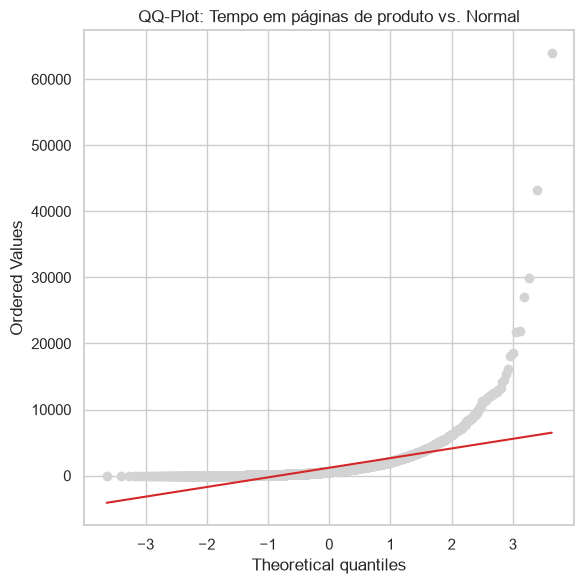

In [18]:
amostra_prd = df["tempo_produto_seg"].sample(5000, random_state=SEED)

stat_sw, p_valor_sw = stats.shapiro(amostra_prd)
print(f"Shapiro-Wilk (amostra n=5000) — tempo_produto_seg: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print("Rejeita H0 (normalidade)?", "Sim" if p_valor_sw < 0.05 else "Não", "(alpha = 0.05)")

stat_dp, p_valor_dp = stats.normaltest(df["tempo_produto_seg"])
print(f"D'Agostino-Pearson (n={len(df)}) — tempo_produto_seg: estatística={stat_dp:.1f}, p-valor={p_valor_dp:.4g}")

fig, ax = plt.subplots(figsize=(6, 6))
stats.probplot(amostra_prd, dist="norm", plot=ax)
ax.get_lines()[0].set_markerfacecolor(COR_NEUTRA)
ax.get_lines()[0].set_markeredgecolor(COR_NEUTRA)
ax.get_lines()[1].set_color(COR_ALERTA)
ax.set_title("QQ-Plot: Tempo em páginas de produto vs. Normal")
plt.tight_layout()
plt.show()

**Como ler:** os pontos formam uma curva que dispara na ponta direita (cauda muito mais pesada que a normal) e ficam "presos" num patamar na esquerda (o piso em 0). O Shapiro-Wilk rejeita a normalidade com folga.

**Nota sobre o tamanho da amostra:** com 12 mil linhas, testes de normalidade ficam sensíveis a desvios triviais. Aqui o desvio **não** é trivial: skewness ≈ 7, QQ-Plot muito curvo e rejeição mesmo na amostra de 5.000. As três evidências concordam: temos evidência estatística **contra** a normalidade.

In [19]:
resultados_shapiro = []
for col in VARS_QUANT:
    stat, p = stats.shapiro(df[col].sample(5000, random_state=SEED))
    resultados_shapiro.append({"variavel": col, "estatistica": round(stat, 4),
                               "p_valor": p, "rejeita_normalidade": p < 0.05})

pd.DataFrame(resultados_shapiro).set_index("variavel")

,estatistica,p_valor,rejeita_normalidade
variavel,,,
paginas_administrativas,0.7296,2.035498e-67,True
tempo_administrativas_seg,0.4672,1.570378e-81,True
paginas_informativas,0.4450,2.016303e-82,True
tempo_informativas_seg,0.2479,3.166806e-89,True
paginas_produto,0.6056,4.180847e-75,True
tempo_produto_seg,0.4840,7.818238e-81,True
taxa_rejeicao,0.4980,3.103988e-80,True
taxa_saida,0.6991,1.497988e-69,True
valor_pagina,0.3507,6.701963e-86,True


Nenhuma variável passa no teste. Isso orienta a escolha de testes **não-paramétricos** (Spearman, Mann-Whitney, Kruskal-Wallis) na Seção 6.

**ECDF — outra forma de ver a distribuição**

A ECDF não depende de bins e é útil para comparar grupos de tamanhos muito diferentes. Usamos `valor_pagina`, a variável que mais separou as classes.

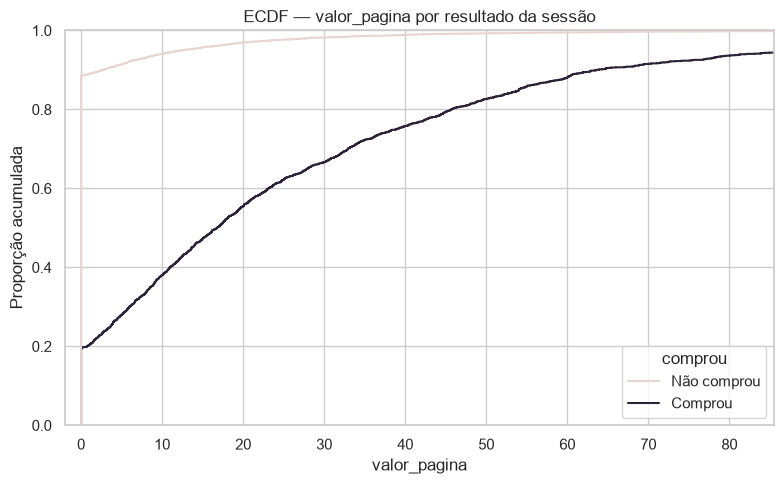

In [20]:
plt.figure(figsize=(8, 5))
sns.ecdfplot(data=df, x="valor_pagina", hue="comprou",
             palette={"Não comprou": COR_CONTEXTO, "Comprou": COR_DESTAQUE})
plt.title("ECDF — valor_pagina por resultado da sessão")
plt.xlabel("valor_pagina")
plt.ylabel("Proporção acumulada")
plt.xlim(-2, df["valor_pagina"].quantile(0.99))
plt.tight_layout()
plt.show()

**Como ler:** a curva rosa já começa perto de **0,9** em `valor_pagina = 0`: quase 9 em cada 10 sessões sem compra não passaram por nenhuma página com valor. A roxa começa bem mais baixo (cerca de 0,2) e sobe aos poucos. A distância vertical entre as curvas é **máxima logo no zero**: o simples fato de `valor_pagina` ser positivo já separa muito as classes.

### Métricas de Tendência Central

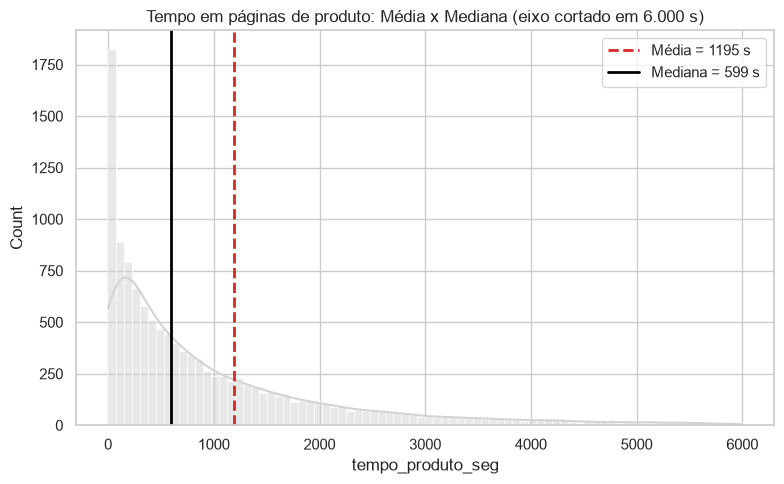

In [21]:
media_prd = df["tempo_produto_seg"].mean()
mediana_prd = df["tempo_produto_seg"].median()

plt.figure(figsize=(8, 5))
sns.histplot(data=df[df["tempo_produto_seg"] <= 6000], x="tempo_produto_seg", bins=80, kde=True, color=COR_NEUTRA)
plt.axvline(media_prd, color=COR_ALERTA, linestyle="--", linewidth=2, label=f"Média = {media_prd:.0f} s")
plt.axvline(mediana_prd, color="black", linestyle="-", linewidth=2, label=f"Mediana = {mediana_prd:.0f} s")
plt.title("Tempo em páginas de produto: Média x Mediana (eixo cortado em 6.000 s)")
plt.legend()
plt.tight_layout()
plt.show()

A média (≈ 1.195 s, ou ~20 min) é o **dobro** da mediana (≈ 599 s, ~10 min). Poucas sessões muito longas, de várias horas, puxam a média. Para descrever a sessão típica, a mediana é a métrica adequada.

### Dispersão

In [22]:
dispersao = df[VARS_QUANT].agg(["var", "std"]).T
dispersao["IQR"] = df[VARS_QUANT].quantile(0.75) - df[VARS_QUANT].quantile(0.25)
dispersao["CV"] = df[VARS_QUANT].std() / df[VARS_QUANT].mean()  # coeficiente de variação
dispersao.round(3)

,var,std,IQR,CV
paginas_administrativas,11.034,3.322,4.000,1.435
tempo_administrativas_seg,31250.853,176.779,93.256,2.187
paginas_informativas,1.613,1.270,0.000,2.522
tempo_informativas_seg,19810.364,140.749,0.000,4.083
paginas_produto,1978.070,44.476,31.000,1.402
tempo_produto_seg,3662130.143,1913.669,1280.020,1.602
taxa_rejeicao,0.002,0.048,0.017,2.185
taxa_saida,0.002,0.049,0.036,1.128
valor_pagina,344.787,18.568,0.000,3.153


`paginas_informativas`, `tempo_informativas_seg` e `valor_pagina` têm **IQR = 0**: mais de 75% das sessões têm valor 0 nelas. A regra do IQR vai marcar **todo valor positivo** como outlier, uma limitação da regra para variáveis com excesso de zeros (discutida na Seção 4). O coeficiente de variação (CV > 1 em quase todas) confirma a dispersão alta em relação à média.

### Boxplot e violin plot por classe

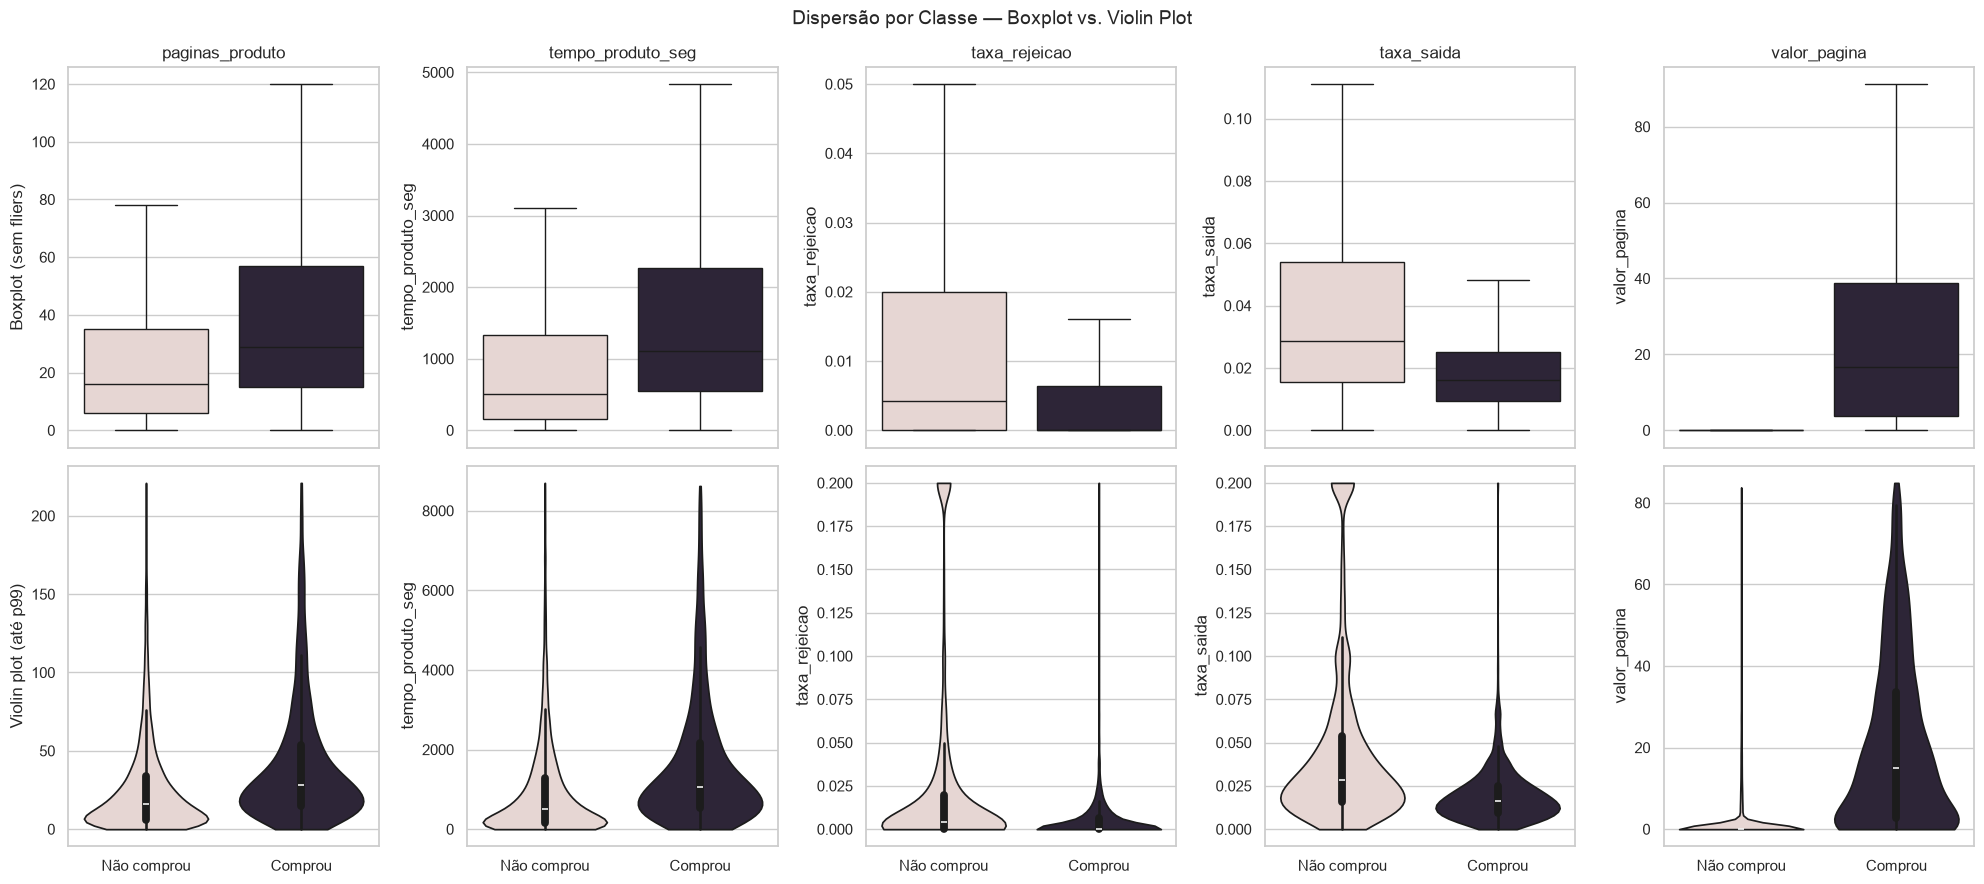

In [23]:
palette_classe = {"Não comprou": COR_CONTEXTO, "Comprou": COR_DESTAQUE}

fig, axes = plt.subplots(2, len(VARS_CORE), figsize=(4 * len(VARS_CORE), 9), sharex="col")

for i, col in enumerate(VARS_CORE):
    sns.boxplot(data=df, x="comprou", y=col, hue="comprou",
                palette=palette_classe, legend=False, showfliers=False, ax=axes[0, i])
    axes[0, i].set_title(col)
    axes[0, i].set_xlabel("")

    dados_p99 = df[df[col] <= df[col].quantile(0.99)]
    sns.violinplot(data=dados_p99, x="comprou", y=col, hue="comprou",
                   palette=palette_classe, legend=False, cut=0, ax=axes[1, i])
    axes[1, i].set_xlabel("")

axes[0, 0].set_ylabel("Boxplot (sem fliers)")
axes[1, 0].set_ylabel("Violin plot (até p99)")
fig.suptitle("Dispersão por Classe — Boxplot vs. Violin Plot", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável mostra uma caixa (IQR) nitidamente mais alta ou mais baixa entre as classes?

*Resposta*: sim, várias. Escondemos os *fliers* e cortamos o violin no p99 para que os extremos não dominem o gráfico. Em **`valor_pagina`**, a caixa de "Não comprou" é um traço em 0, e a de "Comprou" vai de 0 a dezenas. Em **`taxa_saida`**, a caixa de "Comprou" fica inteira abaixo da mediana de "Não comprou". `paginas_produto` e `tempo_produto_seg` têm caixas mais altas entre os compradores (mediana ~29 páginas e ~18 min, contra ~16 páginas e ~8,5 min). São fortes candidatas a diferenciar as classes.

## 4. Tratamento de Dados Ausentes e Outliers

Com o retrato "antes" (Seção 3) e o diagnóstico dos mecanismos de ausência (Seção 2), decidimos o tratamento. Depois, rodamos a estatística descritiva de novo para confirmar o efeito.

### Detecção de Outliers por IQR

A regra clássica marca como outlier qualquer ponto fora de `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]`.

In [24]:
def limites_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

resumo_outliers = {}
for col in VARS_QUANT:
    lim_inf, lim_sup = limites_iqr(df[col])
    n_outliers = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    resumo_outliers[col] = {
        "limite_inferior": round(lim_inf, 3),
        "limite_superior": round(lim_sup, 3),
        "n_outliers": n_outliers,
        "pct_outliers": round(n_outliers / len(df) * 100, 2),
        "maximo": round(df[col].max(), 2),
    }

pd.DataFrame(resumo_outliers).T

,limite_inferior,limite_superior,n_outliers,pct_outliers,maximo
paginas_administrativas,-6.000,10.000,404.0,3.28,27.00
tempo_administrativas_seg,-139.884,233.141,1172.0,9.51,3398.75
paginas_informativas,0.000,0.000,2631.0,21.34,24.00
tempo_informativas_seg,0.000,0.000,2405.0,19.51,2549.38
paginas_produto,-39.500,84.500,987.0,8.00,705.00
tempo_produto_seg,-1735.892,3384.187,961.0,7.79,63973.52
taxa_rejeicao,-0.025,0.042,1551.0,12.58,0.20
taxa_saida,-0.039,0.104,1099.0,8.91,0.20
valor_pagina,0.000,0.000,2730.0,22.14,361.76


### Visualizando os Outliers

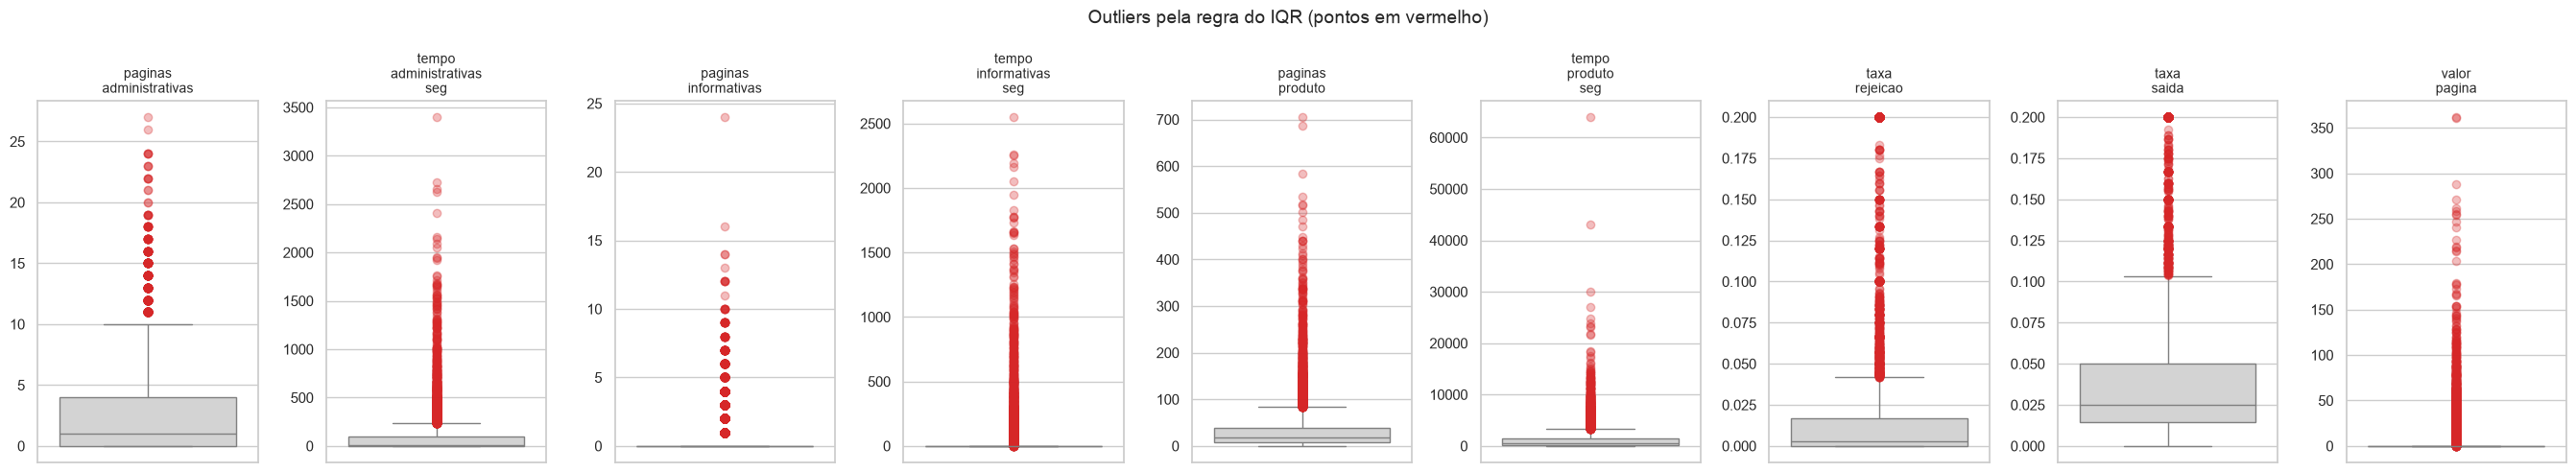

In [25]:
fig, axes = plt.subplots(1, len(VARS_QUANT), figsize=(3 * len(VARS_QUANT), 5))

for i, col in enumerate(VARS_QUANT):
    sns.boxplot(data=df, y=col, color=COR_NEUTRA,
                flierprops=dict(markerfacecolor=COR_ALERTA, markeredgecolor=COR_ALERTA, marker="o", alpha=0.3),
                ax=axes[i])
    axes[i].set_title(col.replace("_", "\n"), fontsize=10)
    axes[i].set_ylabel("")

fig.suptitle("Outliers pela regra do IQR (pontos em vermelho)", fontsize=14)
plt.tight_layout()
plt.show()

In [26]:
# Duração total da sessão, em horas: quantas sessões passam de algumas horas?
duracao_total_h = df[list(pares.values())].sum(axis=1) / 3600
print(duracao_total_h.describe().round(2))
for horas in [1, 3, 6]:
    acima = duracao_total_h > horas
    print(f"Sessões com mais de {horas}h: {acima.sum():4d} | taxa de compra: {(df.loc[acima, 'comprou'] == 'Comprou').mean():.1%}")
print("\nAs 5 sessões mais longas (h):", duracao_total_h.nlargest(5).round(1).tolist())

count    12330.00
mean         0.36
std          0.57
min          0.00
25%          0.06
50%          0.19
75%          0.45
max         19.42
dtype: float64
Sessões com mais de 1h:  987 | taxa de compra: 30.3%
Sessões com mais de 3h:   78 | taxa de compra: 38.5%
Sessões com mais de 6h:   10 | taxa de compra: 20.0%

As 5 sessões mais longas (h): [19.4, 13.3, 9.6, 7.9, 7.2]


**Pra discutir:** classificando os outliers pela tabela da aula 9:

| Tipo | Cenário | O que fazer? |
|---|---|---|
| Estatístico | Legítimo | Manter / Transformar |
| De domínio | Viola regra de negócio ou condições físicas | Investigar! |
| Erros de dados | Falhas | Corrigir se possível / Remover como última opção |

*Resposta*:
- **Contagens de páginas** (`paginas_administrativas` até 27, `paginas_produto` até 705): **estatísticos**. Navegar por centenas de produtos numa sessão é raro, mas possível (comparação de preços, catálogo grande).
- **`paginas_informativas`, `tempo_informativas_seg` e `valor_pagina`**: a regra do IQR marca **todo valor > 0** (IQR = 0). O problema é a regra, não os dados. Esses "outliers" são justamente as sessões mais informativas (em `valor_pagina`, quase todas as compras).
- **`taxa_rejeicao` e `taxa_saida` = 0,2**: não violam nada. 0,2 é o **teto** da métrica nesse dataset, e o acúmulo de valores nele vem das sessões de uma página. São **estatísticos**.
- **Durações de várias horas** (máximo de ~18h numa única sessão): **de domínio**. Ninguém navega 18h seguidas. O mais provável é uma aba esquecida aberta, com o GA contando o tempo até o próximo clique. Mesmo assim, essas sessões **convertem acima da média**: o visitante voltou à aba e comprou. Não são erros de digitação, e sim tempo "inflado" por inatividade.

### Decidindo o Tratamento dos Dados Ausentes

Reunindo o diagnóstico da Seção 2:

| Problema | Mecanismo provável | Volume | Tratamento |
|---|---|---|---|
| Tempo = 0 com páginas vistas | MNAR (instrumento de medição) | 717 sessões em produto | **Manter** o 0 e criar a flag `tempo_nao_medido`. Imputar inventaria um tempo que ninguém mediu; remover inflaria a conversão |
| Sessões com 0 páginas | Erro de dados | 6 sessões | **Remover** |
| Janeiro e abril | Recorte da coleta | 2 meses | Sem tratamento possível; registrar como **limitação** |

In [27]:
linhas_antes = df.shape[0]
df_antes = df.copy()

# Sessões sem nenhuma página: erro de dados -> remover
df = df[df[list(pares)].sum(axis=1) > 0].reset_index(drop=True)

# Tempo não medido (MNAR): mantém o 0 e sinaliza com uma flag
df["tempo_nao_medido"] = np.where(
    ((df[list(pares)].values > 0) & (df[list(pares.values())].values == 0)).any(axis=1), "Sim", "Não"
)

linhas_depois = df.shape[0]
print(f"Linhas antes: {linhas_antes} | Linhas depois: {linhas_depois} | Removidas: {linhas_antes - linhas_depois}")
print(df["tempo_nao_medido"].value_counts())

Linhas antes: 12330 | Linhas depois: 12324 | Removidas: 6
tempo_nao_medido
Não    11255
Sim     1069
Name: count, dtype: int64


### Decidindo o Tratamento dos Outliers

Como nos dados de aula, **não removemos automaticamente**. Os outliers de contagem, taxa e valor são **estatísticos** e informativos (em `valor_pagina`, são a própria assinatura da compra), então ficam. As sessões de várias horas são **de domínio**: o tempo está inflado por inatividade. Como não sabemos o tempo "real", também **mantemos**, mas registramos que médias de duração devem ser lidas com cuidado (a mediana é robusta a elas).

Como opção para análises futuras, ilustramos a transformação logarítmica em `tempo_produto_seg`.

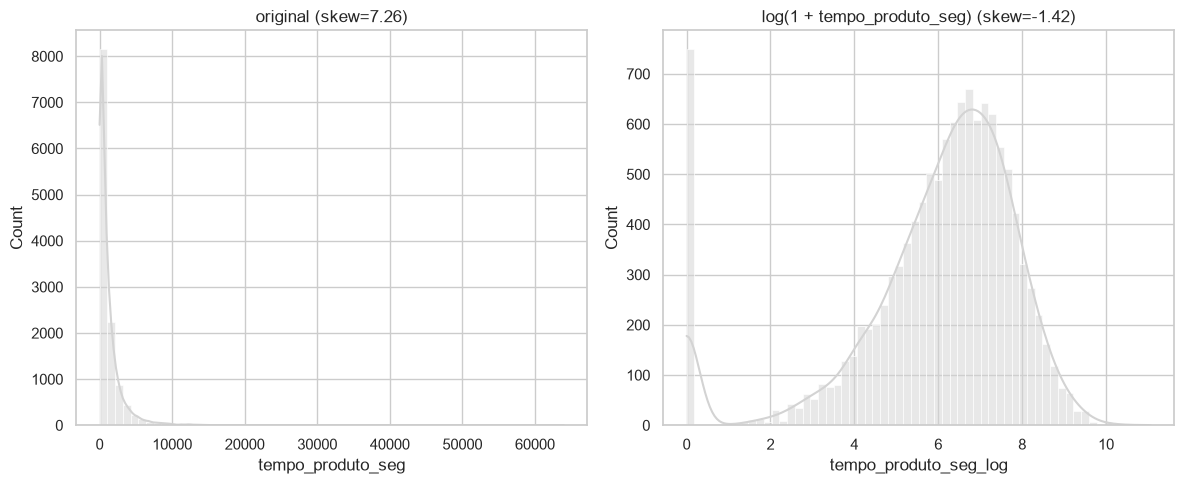

In [28]:
df["tempo_produto_seg_log"] = np.log1p(df["tempo_produto_seg"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.histplot(data=df, x="tempo_produto_seg", bins=60, kde=True, color=COR_NEUTRA, ax=axes[0])
axes[0].set_title(f"original (skew={df['tempo_produto_seg'].skew():.2f})")

sns.histplot(data=df, x="tempo_produto_seg_log", bins=60, kde=True, color=COR_NEUTRA, ax=axes[1])
axes[1].set_title(f"log(1 + tempo_produto_seg) (skew={df['tempo_produto_seg_log'].skew():.2f})")

plt.tight_layout()
plt.show()

**Pra discutir:** a transformação logarítmica reduziu visivelmente a assimetria?

*Resposta*: sim. A cauda longa à direita some e a distribuição fica parecida com um sino, mas surge uma **barra isolada em 0**: são as sessões de `tempo_nao_medido`, que o log não tem como "espalhar". Isso reforça que o 0 dessas sessões é outra coisa (ausência de medida) e não o começo de uma escala contínua. Mantemos a coluna `_log` como auxiliar, mas as próximas seções usam a variável original.

## 5. Estatística Descritiva pt 2

Fechando o ciclo iterativo: removemos 6 sessões inválidas e mantivemos os outliers. Rodamos a mesma bateria da Seção 3 para comparar com o "antes".

In [29]:
desc_depois = df[VARS_QUANT].describe().T
desc_depois["skewness"] = df[VARS_QUANT].skew()
desc_depois["kurtosis"] = df[VARS_QUANT].kurtosis()

(
    desc_depois[["mean", "50%", "std", "min", "max", "skewness", "kurtosis"]]
    .rename(columns={"50%": "median"})
    .round(3)
    .style.format(precision=3)
    .background_gradient(cmap="Blues", subset=["skewness", "kurtosis"])
)

,mean,median,std,min,max,skewness,kurtosis
paginas_administrativas,2.316,1.000,3.322,0.000,27.000,1.960,4.698
tempo_administrativas_seg,80.858,7.612,176.813,0.000,3398.750,5.615,50.537
paginas_informativas,0.504,0.000,1.270,0.000,24.000,4.035,26.919
tempo_informativas_seg,34.489,0.000,140.781,0.000,2549.375,7.577,76.279
paginas_produto,31.747,18.000,44.481,0.000,705.000,4.341,31.206
tempo_produto_seg,1195.328,599.217,1913.953,0.000,63973.522,7.263,137.150
taxa_rejeicao,0.022,0.003,0.048,0.000,0.200,2.958,7.792
taxa_saida,0.043,0.025,0.048,0.000,0.200,2.153,4.046
valor_pagina,5.892,0.000,18.573,0.000,361.764,6.381,65.605


### Comparando "antes" x "depois"

In [30]:
comparacao = pd.DataFrame({
    "skewness_antes": desc["skewness"],
    "skewness_depois": desc_depois["skewness"],
    "kurtosis_antes": desc["kurtosis"],
    "kurtosis_depois": desc_depois["kurtosis"],
})
comparacao["delta_skewness"] = (comparacao["skewness_depois"] - comparacao["skewness_antes"]).round(3)
comparacao["delta_kurtosis"] = (comparacao["kurtosis_depois"] - comparacao["kurtosis_antes"]).round(3)
comparacao.round(3)

,skewness_antes,skewness_depois,kurtosis_antes,kurtosis_depois,delta_skewness,delta_kurtosis
paginas_administrativas,1.960,1.960,4.701,4.698,-0.001,-0.003
tempo_administrativas_seg,5.616,5.615,50.557,50.537,-0.001,-0.020
paginas_informativas,4.036,4.035,26.932,26.919,-0.001,-0.013
tempo_informativas_seg,7.579,7.577,76.317,76.279,-0.002,-0.038
paginas_produto,4.342,4.341,31.212,31.206,-0.000,-0.006
tempo_produto_seg,7.263,7.263,137.174,137.150,-0.000,-0.024
taxa_rejeicao,2.948,2.958,7.723,7.792,0.010,0.069
taxa_saida,2.149,2.153,4.017,4.046,0.004,0.029
valor_pagina,6.383,6.381,65.636,65.605,-0.002,-0.031


**Pra discutir:** os valores mudaram muito?

*Resposta*: praticamente nada. Removemos 6 de 12.330 linhas (0,05%) e não alteramos nenhum outlier. As diferenças aparecem só na terceira casa decimal. Isso **confirma** que o tratamento foi conservador e não deformou as distribuições. O "trabalho" desta etapa foi de **diagnóstico** (entender o que significa um 0 ou um 0,2), mais do que de alteração dos dados.

**O tempo em produto ainda rejeita normalidade?**

In [31]:
stat_sw_depois, p_valor_sw_depois = stats.shapiro(df["tempo_produto_seg"].sample(5000, random_state=SEED))
print(f"Shapiro-Wilk (antes)  — tempo_produto_seg: estatística={stat_sw:.4f}, p-valor={p_valor_sw:.4g}")
print(f"Shapiro-Wilk (depois) — tempo_produto_seg: estatística={stat_sw_depois:.4f}, p-valor={p_valor_sw_depois:.4g}")

Shapiro-Wilk (antes)  — tempo_produto_seg: estatística=0.4840, p-valor=7.818e-81
Shapiro-Wilk (depois) — tempo_produto_seg: estatística=0.5168, p-valor=2.058e-79


**Visualizando antes x depois, lado a lado**

Sobrepomos as distribuições de `tempo_produto_seg` e `taxa_saida`, comparando `df_antes` com o `df` tratado.

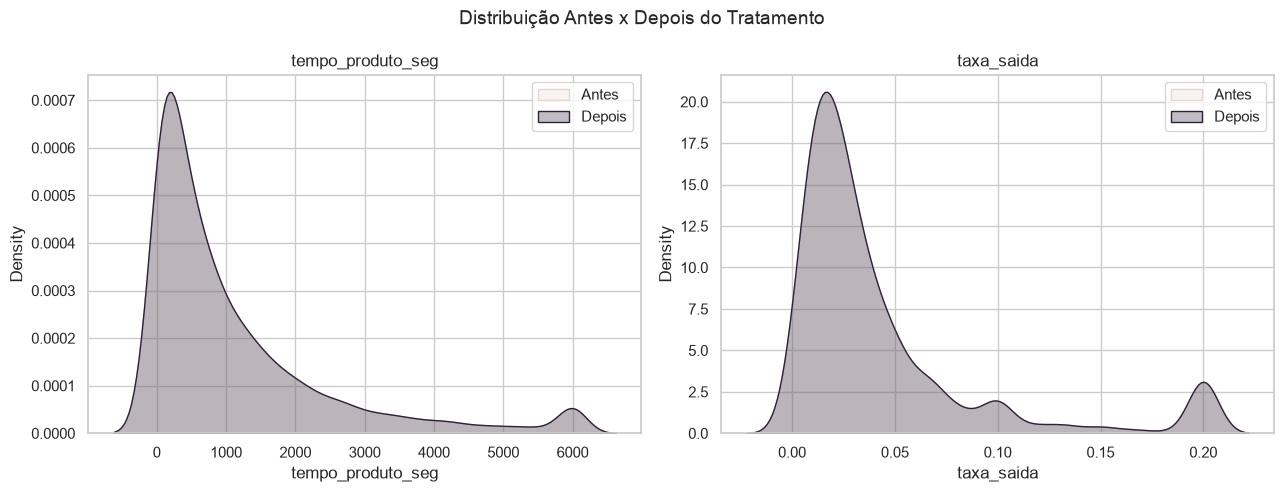

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, col, lim in zip(axes, ["tempo_produto_seg", "taxa_saida"], [6000, 0.2]):
    sns.kdeplot(df_antes[col].clip(upper=lim), color=COR_CONTEXTO, fill=True, label="Antes", ax=ax)
    sns.kdeplot(df[col].clip(upper=lim), color=COR_DESTAQUE, fill=True, alpha=0.3, label="Depois", ax=ax)
    ax.set_title(col)
    ax.legend()

fig.suptitle("Distribuição Antes x Depois do Tratamento", fontsize=14)
plt.tight_layout()
plt.show()

**Pra discutir:** as curvas "antes" e "depois" se sobrepõem?

*Resposta*: sim, completamente, como esperado. Note também o pequeno pico de `taxa_saida` em 0,2 (o teto da métrica), presente nas duas versões.

## 6. Princípio Relacional

### Análise de Variáveis Qualitativas

Avaliação de frequência e desbalanceamento das variáveis qualitativas.

#### Frequências absolutas e relativas

In [33]:
for col in VARS_QUALI:
    freq_abs = df[col].value_counts()
    freq_rel = df[col].value_counts(normalize=True).round(3)
    print(f"\n--- {col} ---")
    print(pd.concat([freq_abs.rename("absoluta"), freq_rel.rename("relativa")], axis=1))


--- mes ---
     absoluta  relativa
mes                    
Mai      3362     0.273
Nov      2995     0.243
Mar      1907     0.155
Dez      1727     0.140
Out       549     0.045
Set       448     0.036
Ago       433     0.035
Jul       432     0.035
Jun       287     0.023
Fev       184     0.015

--- tipo_visitante ---
                absoluta  relativa
tipo_visitante                    
Recorrente         10545     0.856
Novo                1694     0.137
Outro                 85     0.007

--- fim_de_semana ---
               absoluta  relativa
fim_de_semana                    
Não                9457     0.767
Sim                2867     0.233

--- proximidade_data_especial ---
                           absoluta  relativa
proximidade_data_especial                    
0.0                           11073     0.898
0.6                             351     0.028
0.8                             325     0.026
0.4                             243     0.020
0.2                           

#### Visualizando as frequências

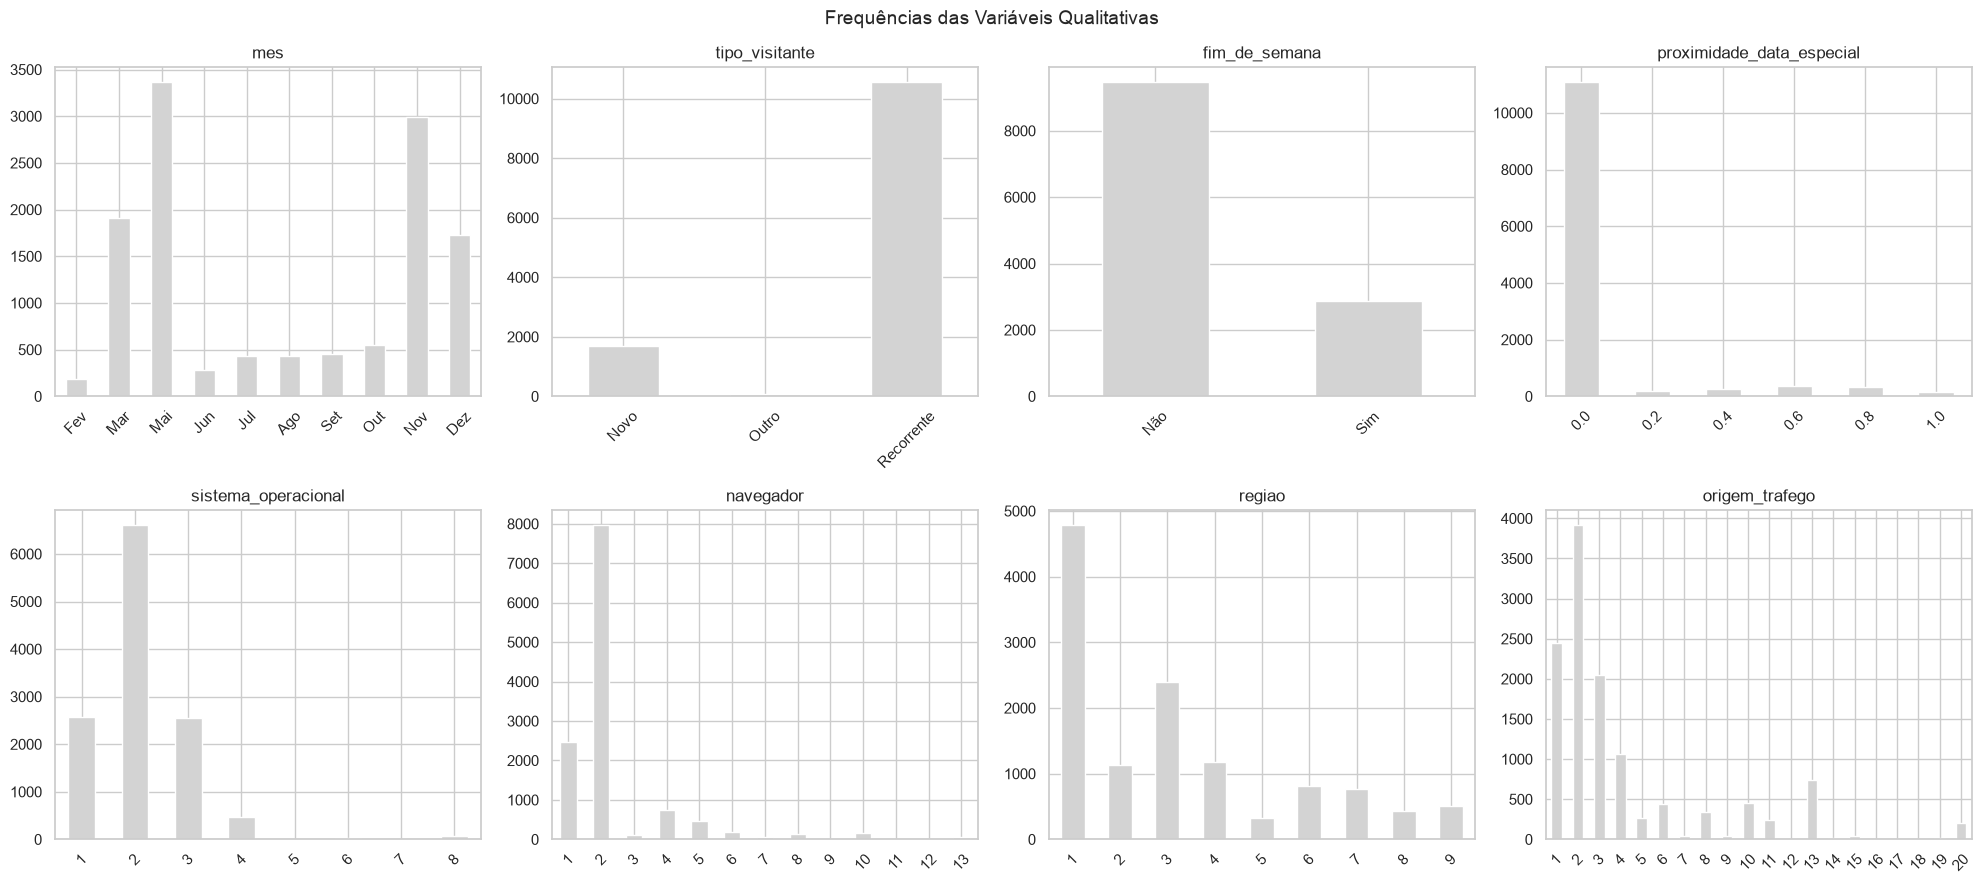

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
axes = axes.ravel()

for i, col in enumerate(VARS_QUALI):
    contagem = df[col].value_counts()
    if col == "mes":
        contagem = contagem.reindex([m for m in ordem_meses if m in contagem.index])
    elif col in ["sistema_operacional", "navegador", "regiao", "origem_trafego"]:
        contagem = contagem.sort_index(key=lambda idx: idx.astype(int))
    else:
        contagem = contagem.sort_index()
    contagem.plot(kind="bar", color=COR_NEUTRA, ax=axes[i])
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].tick_params(axis="x", rotation=45)

fig.suptitle("Frequências das Variáveis Qualitativas", fontsize=14)
plt.tight_layout()
plt.show()

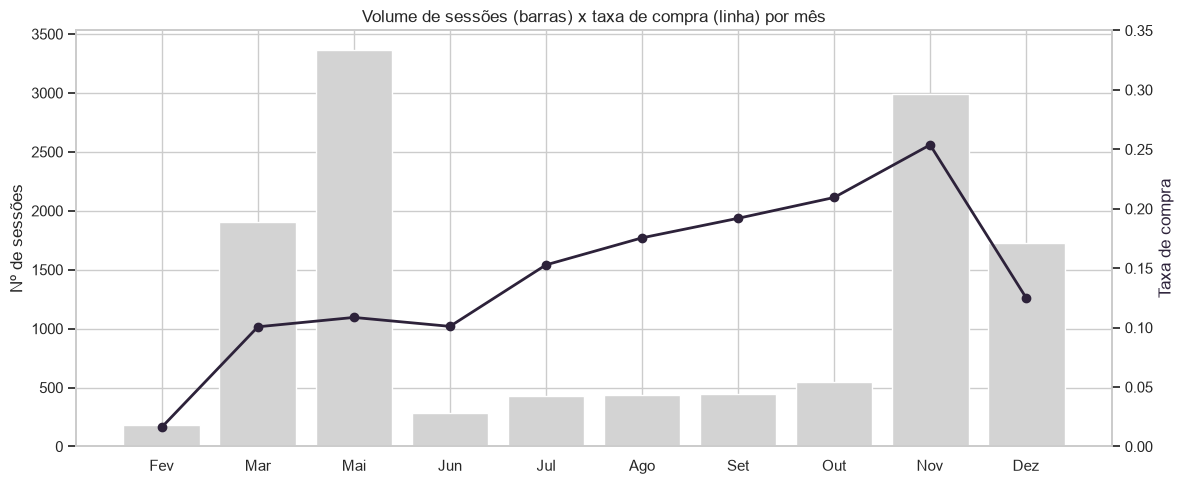

In [35]:
# Aspecto temporal: volume de sessões e taxa de compra por mês
por_mes = df.groupby("mes").agg(
    sessoes=("comprou", "size"),
    taxa_compra=("comprou", lambda s: (s == "Comprou").mean()),
).reindex([m for m in ordem_meses if m in df["mes"].unique()])

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.bar(por_mes.index, por_mes["sessoes"], color=COR_NEUTRA)
ax1.set_ylabel("Nº de sessões")
ax2 = ax1.twinx()
ax2.plot(por_mes.index, por_mes["taxa_compra"], color=COR_DESTAQUE, marker="o", linewidth=2)
ax2.set_ylabel("Taxa de compra", color=COR_DESTAQUE)
ax2.set_ylim(0, 0.35)
ax2.grid(False)
ax1.set_title("Volume de sessões (barras) x taxa de compra (linha) por mês")
plt.tight_layout()
plt.show()

**Pra discutir:** alguma variável qualitativa está bem desbalanceada?

*Resposta*: sim. `tipo_visitante` é dominada por visitantes recorrentes (~86%). `proximidade_data_especial` é ~90% zero. Os códigos técnicos têm caudas longas de categorias raras: há navegadores e tipos de tráfego com 1 a 10 sessões. Cruzamentos com essas categorias terão pouquíssimos casos e taxas instáveis (uma categoria com 1 sessão tem taxa de compra de 0% ou 100%).

No tempo, **maio** e **novembro** concentram o maior volume, mas com comportamentos opostos: novembro tem a **maior** taxa de compra (~25%, provavelmente a temporada de Black Friday e pré-Natal), enquanto maio, mesmo com mais sessões, converte só ~11%. **Fevereiro** quase não converte (~2%).

#### Desbalanceamento entre Classes

- **Razão de desbalanceamento**: # classe majoritária / # classe minoritária (quanto maior, mais desbalanceado).
- **Entropia de Shannon normalizada**: 1 = perfeitamente balanceado, 0 = uma classe domina tudo.

In [36]:
from scipy.stats import entropy

def metrica_desbalanceamento(serie):
    contagens = serie.value_counts()
    razao = contagens.max() / contagens.min()
    props = contagens / contagens.sum()
    n_classes = len(contagens)
    ent_normalizada = entropy(props, base=2) / np.log2(n_classes) if n_classes > 1 else np.nan
    return pd.Series({
        "n_classes": n_classes,
        "razao_desbalanceamento": round(razao, 2),
        "entropia_normalizada": round(ent_normalizada, 3),
    })

vars_para_checar = VARS_QUALI + ["comprou"]
pd.DataFrame({col: metrica_desbalanceamento(df[col]) for col in vars_para_checar}).T

,n_classes,razao_desbalanceamento,entropia_normalizada
mes,10.0,18.27,0.828
tipo_visitante,3.0,124.06,0.401
fim_de_semana,2.0,3.30,0.783
proximidade_data_especial,6.0,71.90,0.272
sistema_operacional,8.0,1099.83,0.560
navegador,13.0,7958.00,0.453
regiao,9.0,15.03,0.830
origem_trafego,20.0,3912.00,0.671
comprou,2.0,5.46,0.622


**Pra discutir:** alguma variável está com entropia bem próxima de 0? E o próprio alvo?

*Resposta*: as razões de desbalanceamento de `navegador` e `origem_trafego` são enormes (milhares para 1) por causa de categorias com 1 sessão. Isso é efeito das categorias raras, não de uma única classe dominante, e a entropia delas não é tão baixa. As menores entropias são as de `proximidade_data_especial` e `tipo_visitante`. O **alvo `comprou` é desbalanceado**: só ~15,5% das sessões terminam em compra (razão ≈ 5,5:1, entropia ≈ 0,62). Por isso comparamos **proporções/densidades**. Num modelo futuro, prever "não comprou" para todo mundo já daria ~85% de acurácia, então seria preciso usar precisão/recall/F1 ou AUC.

### Análise Bivariada

Agora avaliamos como as variáveis se relacionam entre si e com o alvo `comprou`.

#### Quantitativa x Quantitativa - Correlação

* **Pearson** (linear, sensível a outliers, exige normalidade),
* **Spearman** e **Kendall** (relação monotônica, não exigem normalidade).

Como nenhuma variável passou no Shapiro-Wilk, **Spearman** é a escolha mais segura, mas calculamos as três para comparar.

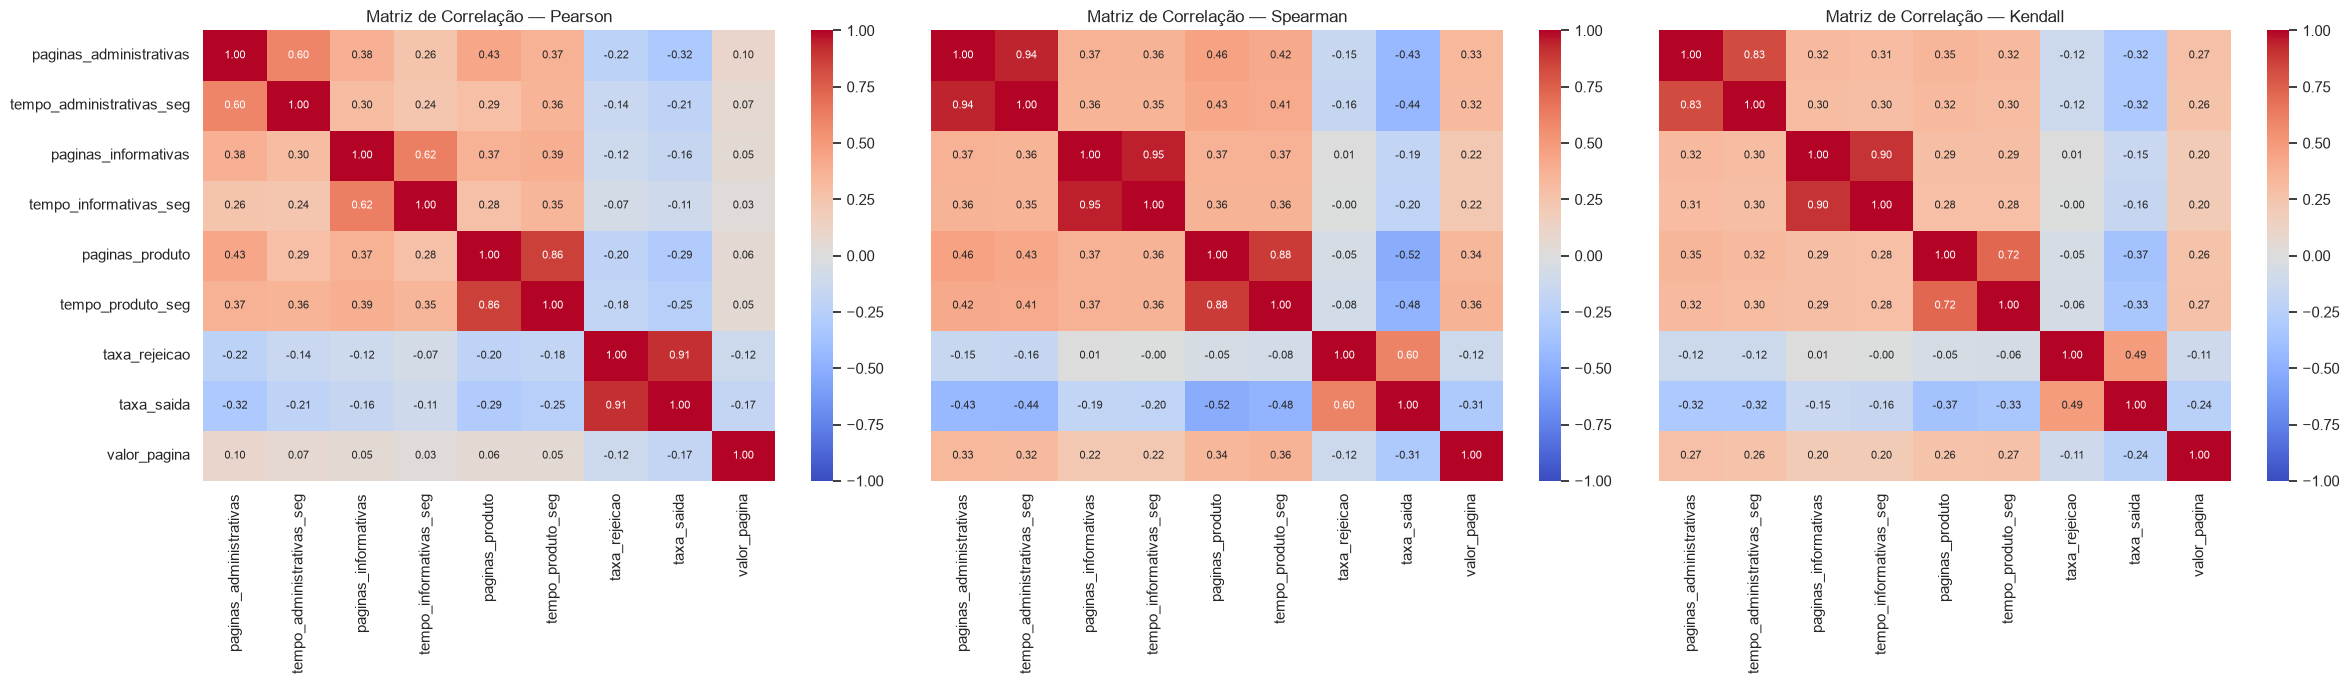

In [37]:
corr_pearson = df[VARS_QUANT].corr(method="pearson")
corr_spearman = df[VARS_QUANT].corr(method="spearman")
corr_kendall = df[VARS_QUANT].corr(method="kendall")

rotulos = VARS_QUANT
fig, ax = plt.subplots(1, 3, figsize=(24, 7), sharey=True)
for eixo, (nome, matriz) in zip(ax, [("Pearson", corr_pearson), ("Spearman", corr_spearman), ("Kendall", corr_kendall)]):
    sns.heatmap(matriz, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=eixo,
                xticklabels=rotulos, yticklabels=rotulos, annot_kws={"size": 8})
    eixo.set_title(f"Matriz de Correlação — {nome}")
plt.tight_layout()
plt.show()

Como a matriz é simétrica, podemos plotar só o triângulo inferior:

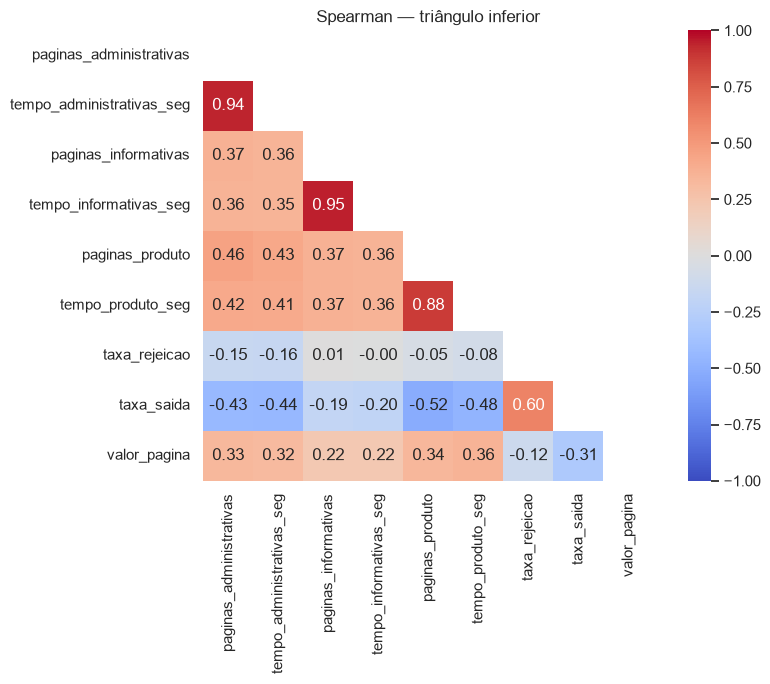

In [38]:
mask = np.triu(np.ones_like(corr_spearman, dtype=bool))

plt.figure(figsize=(9, 7))
sns.heatmap(corr_spearman, mask=mask, annot=True, cmap="coolwarm", fmt=".2f", square=True, vmin=-1, vmax=1,
            xticklabels=rotulos, yticklabels=rotulos)
plt.grid(False)
plt.title("Spearman — triângulo inferior")
plt.tight_layout()
plt.show()

**Pra discutir:** Pearson e Spearman divergem bastante em algum par?

*Resposta*: sim, e nos **dois sentidos**, o que é instrutivo:

- **Spearman > Pearson** nas contagens x durações: `paginas_administrativas` x `tempo_administrativas_seg` (0,94 vs 0,60) e `paginas_informativas` x `tempo_informativas_seg` (0,95 vs 0,62). As durações têm caudas extremas (sessões de horas) que "desalinham" a relação linear, enquanto o Spearman, baseado em postos, enxerga a relação monotônica: mais páginas, mais tempo. O mesmo vale para `taxa_saida` x `paginas_produto` (−0,52 vs −0,29).
- **Pearson > Spearman** em `taxa_rejeicao` x `taxa_saida` (0,91 vs 0,60). Aqui o Pearson é **inflado** pelo bloco de ~700 sessões de uma página que estão exatamente em (0,2; 0,2), longe de todo o resto: poucos pontos extremos alinhados criam uma "reta" artificial. O Spearman mostra que, na massa dos dados, a relação é moderada.

Ou seja, outliers tanto podem **esconder** quanto **fabricar** correlação linear. Por isso o Spearman é a referência daqui em diante. As três contagens com suas durações são praticamente **redundantes** (ρ ≥ 0,88).

#### Dispersão (scatter) entre duas variáveis quantitativas

Escolhemos `taxa_rejeicao` x `taxa_saida` por motivo de domínio: são as duas métricas de abandono do GA, conceitualmente ligadas. Também é um dos pares com maior |correlação| que não envolve uma contagem e sua própria duração.

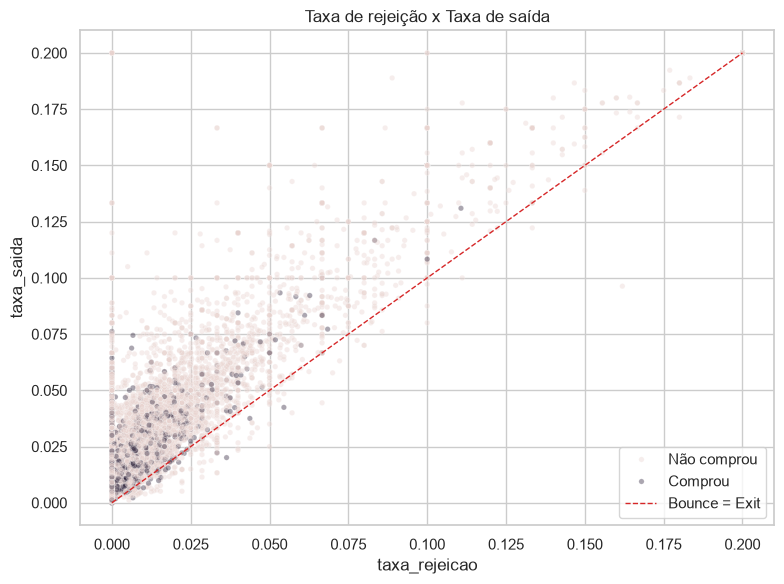

In [39]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="taxa_rejeicao", y="taxa_saida", hue="comprou",
                palette=palette_classe, alpha=0.4, s=15)
plt.plot([0, 0.2], [0, 0.2], color=COR_ALERTA, linestyle="--", linewidth=1, label="Bounce = Exit")
plt.title("Taxa de rejeição x Taxa de saída")
plt.legend()
plt.tight_layout()
plt.show()

**Pra discutir:** existe uma tendência visível? As classes ocupam regiões diferentes?

*Resposta*: há uma tendência positiva clara, e ~99% dos pontos ficam **sobre ou acima** da diagonal (taxa de saída ≥ taxa de rejeição), o que faz sentido: toda rejeição é uma saída, mas nem toda saída é rejeição. Aparece um acúmulo no canto (0,2; 0,2): as sessões de uma página que bateram no teto das duas métricas. As classes ocupam regiões bem diferentes: as compras (roxo) se concentram perto da origem (rejeição e saída baixas) e praticamente somem quando `taxa_saida` passa de 0,1 (menos de 1% de compra nessa faixa).

#### Quantitativa x Qualitativa: Comparando Grupos

Como nenhuma quantitativa é normal, reportamos os testes **não-paramétricos**: **Mann-Whitney U** (2 grupos) e **Kruskal-Wallis** (3+ grupos). Os paramétricos (T-Test de Welch e ANOVA) ficam como contraste.

Com 12 mil linhas, quase qualquer diferença vira "significativa". Por isso acrescentamos um **tamanho de efeito**, a correlação rank-biserial (r = 1 − 2U/(n₁n₂), de −1 a 1; positivo = maior entre quem comprou).

In [40]:
resultados_comparacao = []
for col in VARS_QUANT:
    grupo_nao = df.loc[df["comprou"] == "Não comprou", col]
    grupo_sim = df.loc[df["comprou"] == "Comprou", col]

    stat_t, p_t = stats.ttest_ind(grupo_nao, grupo_sim, equal_var=False)  # Welch (paramétrico)
    stat_u, p_u = stats.mannwhitneyu(grupo_nao, grupo_sim)                 # não-paramétrico
    rank_biserial = 1 - 2 * stat_u / (len(grupo_nao) * len(grupo_sim))      # tamanho de efeito

    resultados_comparacao.append({
        "variavel": col,
        "mediana_nao_comprou": round(grupo_nao.median(), 3),
        "mediana_comprou": round(grupo_sim.median(), 3),
        "p_valor_ttest": p_t,
        "p_valor_mannwhitney": p_u,
        "concordam": (p_t < 0.05) == (p_u < 0.05),
        "efeito_rank_biserial": round(rank_biserial, 3),
    })

pd.DataFrame(resultados_comparacao).set_index("variavel").sort_values("efeito_rank_biserial", key=abs, ascending=False)

,mediana_nao_comprou,mediana_comprou,p_valor_ttest,p_valor_mannwhitney,concordam,efeito_rank_biserial
variavel,,,,,,
valor_pagina,0.000,16.758,9.920958e-174,0.000000e+00,True,0.727
taxa_saida,0.029,0.016,0.000000e+00,2.347959e-175,True,-0.406
tempo_produto_seg,511.350,1109.906,2.539717e-45,1.023676e-127,True,0.346
paginas_produto,16.000,29.000,1.036445e-42,1.962510e-107,True,0.316
paginas_administrativas,0.000,2.000,5.973749e-43,2.007515e-77,True,0.253
tempo_administrativas_seg,0.000,52.367,2.363636e-20,7.028069e-74,True,0.247
taxa_rejeicao,0.004,0.000,6.619817e-252,3.114630e-61,True,-0.226
paginas_informativas,0.000,0.000,2.234269e-19,1.430267e-36,True,0.130
tempo_informativas_seg,0.000,0.000,4.919029e-11,1.656783e-35,True,0.124


**Pra discutir:** os dois testes concordam?

*Resposta*: concordam em **todas** as 9 variáveis: as duas classes diferem significativamente em tudo. Com n ≈ 12 mil, isso diz pouco sozinho. O que ordena a importância é o **tamanho do efeito**:
- **`valor_pagina`** tem efeito muito grande (r ≈ 0,73): a mediana de quem não comprou é 0, e a de quem comprou é ~16,8.
- **`taxa_saida`** (r ≈ −0,41) e **`tempo_produto_seg`/`paginas_produto`** (≈ 0,35/0,32) têm efeitos moderados: quem compra sai menos e navega mais por produtos.
- As páginas **informativas** têm efeito pequeno (≈ 0,13), mesmo com p-valores minúsculos. Significância estatística ≠ relevância prática.

O Mann-Whitney é o que reportamos, por respeitar a não-normalidade. Aqui o T-Test chegou à mesma conclusão, mas por sorte: as premissas dele não valem para esses dados.

*Exemplo com 3+ grupos — ANOVA x Kruskal-Wallis*

`tipo_visitante` tem 3 categorias (novo, recorrente, outro). Testamos se o tempo em páginas de produto difere entre elas.

ANOVA          — tempo_produto_seg entre tipo_visitante: estatística=91.018, p-valor=5.7607e-40
Kruskal-Wallis — tempo_produto_seg entre tipo_visitante: estatística=185.678, p-valor=4.7929e-41
tipo_visitante
Novo          414.2
Outro         136.5
Recorrente    655.9
Name: tempo_produto_seg, dtype: float64


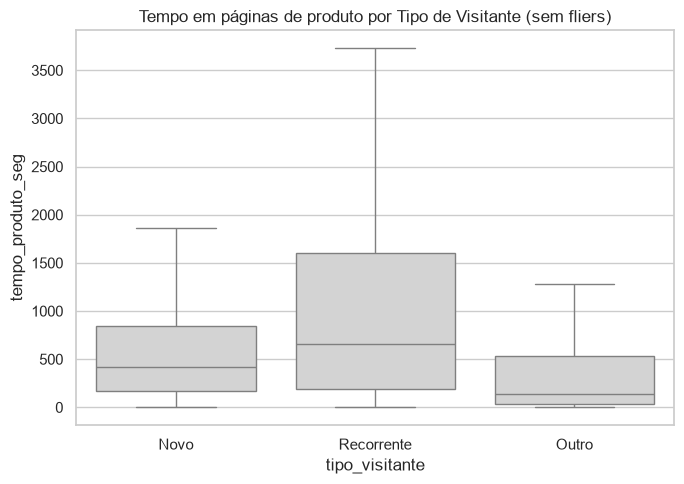

In [41]:
ordem_visitante = ["Novo", "Recorrente", "Outro"]
grupos_visitante = [df.loc[df["tipo_visitante"] == tipo, "tempo_produto_seg"].values for tipo in ordem_visitante]

stat_anova, p_anova = stats.f_oneway(*grupos_visitante)   # paramétrico
stat_kw, p_kw = stats.kruskal(*grupos_visitante)          # não-paramétrico

print(f"ANOVA          — tempo_produto_seg entre tipo_visitante: estatística={stat_anova:.3f}, p-valor={p_anova:.5g}")
print(f"Kruskal-Wallis — tempo_produto_seg entre tipo_visitante: estatística={stat_kw:.3f}, p-valor={p_kw:.5g}")
print(df.groupby("tipo_visitante")["tempo_produto_seg"].median().round(1))

plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x="tipo_visitante", y="tempo_produto_seg", order=ordem_visitante, color=COR_NEUTRA, showfliers=False)
plt.title("Tempo em páginas de produto por Tipo de Visitante (sem fliers)")
plt.tight_layout()
plt.show()

**Pra discutir:** o Kruskal-Wallis concorda com a ANOVA?

*Resposta*: sim, os dois rejeitam a igualdade (p ≈ 1e-40), e reportamos o **Kruskal-Wallis**, já que a variável é muito assimétrica. Pelas medianas, quem passa **mais** tempo em produtos é o visitante **recorrente** (~656 s), seguido do novo (~414 s). A categoria `Outro` (~137 s) tem só 85 sessões. Curiosamente, o visitante recorrente navega mais, mas compra **menos** (veja abaixo): mais tempo de navegação não significa, sozinho, mais conversão.

#### Qualitativa x Qualitativa

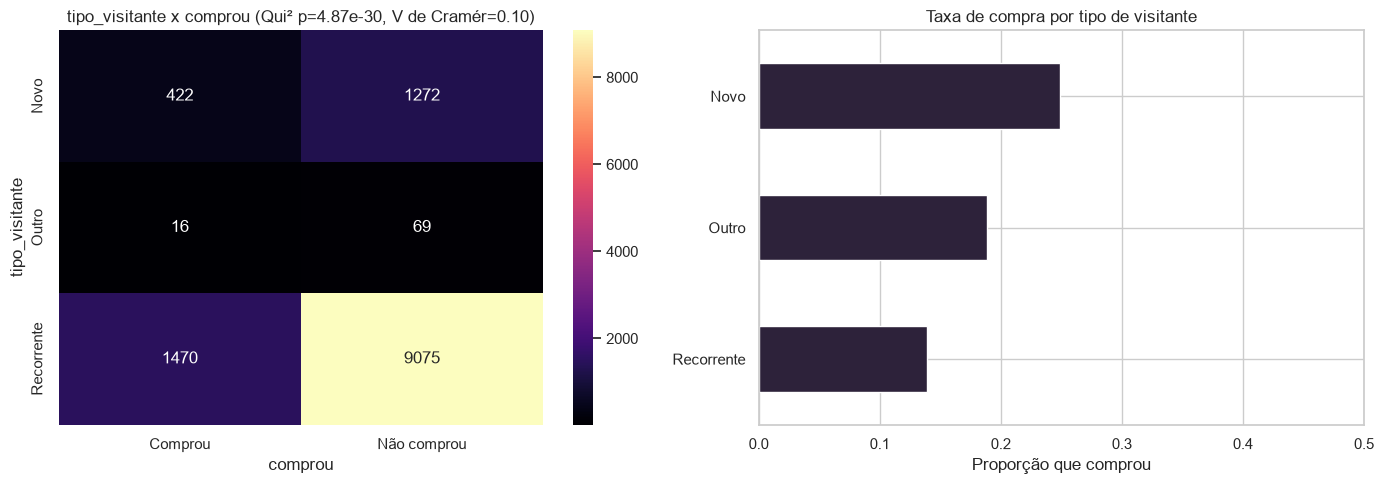

In [42]:
contingencia_visitante = pd.crosstab(df["tipo_visitante"], df["comprou"])
chi2, p_chi2, gl, esperado = stats.chi2_contingency(contingencia_visitante)

# V de Cramér: tamanho de efeito para o Qui-Quadrado (0 = sem associação, 1 = associação perfeita)
v_cramer = np.sqrt(chi2 / (contingencia_visitante.values.sum() * (min(contingencia_visitante.shape) - 1)))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(contingencia_visitante, annot=True, fmt="d", cmap="magma", ax=axes[0])
axes[0].set_title(f"tipo_visitante x comprou (Qui² p={p_chi2:.3g}, V de Cramér={v_cramer:.2f})")

pd.crosstab(df["tipo_visitante"], df["comprou"], normalize="index")["Comprou"].sort_values().plot(
    kind="barh", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Taxa de compra por tipo de visitante")
axes[1].set_xlim(0, 0.5)
axes[1].set_xlabel("Proporção que comprou")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()

**Pra discutir:** `tipo_visitante` e `comprou` são independentes?

*Resposta*: não são independentes (p muito pequeno), mas a associação é **fraca** (V de Cramér ≈ 0,10). O padrão é contraintuitivo: **visitantes novos compram mais** (~25%) que os recorrentes (~14%). Uma hipótese de domínio: o visitante novo muitas vezes chega por um anúncio ou busca já com intenção de compra, enquanto o recorrente também volta só para pesquisar, comparar preços ou acompanhar um pedido. Além disso, quase todos os visitantes novos estão em poucos meses (nov, dez, mai, mar), então parte do efeito pode vir da **sazonalidade**.

In [43]:
# Panorama: associação de cada qualitativa com o alvo (Qui² + V de Cramér)
associacoes = []
for col in VARS_QUALI + ["tempo_nao_medido"]:
    tab = pd.crosstab(df[col], df["comprou"])
    chi2_c, p_c, _, esperado_c = stats.chi2_contingency(tab)
    associacoes.append({"variavel": col, "n_categorias": tab.shape[0], "p_valor": p_c,
                        "v_cramer": np.sqrt(chi2_c / (tab.values.sum() * (min(tab.shape) - 1))),
                        "pct_celulas_esperado_<5": (esperado_c < 5).mean() * 100})

pd.DataFrame(associacoes).set_index("variavel").sort_values("v_cramer", ascending=False).round(4)

,n_categorias,p_valor,v_cramer,pct_celulas_esperado_<5
variavel,,,,
mes,10,0.0000,0.1768,0.0000
origem_trafego,20,0.0000,0.1740,22.5000
tipo_visitante,3,0.0000,0.1047,0.0000
proximidade_data_especial,6,0.0000,0.0883,0.0000
sistema_operacional,8,0.0000,0.0780,18.7500
tempo_nao_medido,2,0.0000,0.0614,0.0000
navegador,13,0.0062,0.0474,15.3846
fim_de_semana,2,0.0013,0.0290,0.0000
regiao,9,0.3266,0.0273,0.0000


Todas são significativas a 5%, exceto **`regiao`** (p ≈ 0,33). Pelo V de Cramér, as mais associadas à compra são **`mes`** (≈ 0,18) e **`origem_trafego`** (≈ 0,17), seguidas de `tipo_visitante` (≈ 0,10) e `proximidade_data_especial` (≈ 0,09). Todas as associações qualitativas são **fracas**, bem menores que o efeito de `valor_pagina` ou `taxa_saida`: **o que o visitante faz** na sessão diz muito mais do que **quem/de onde** ele é.

**Atenção à coluna `pct_celulas_esperado_<5`:** em `origem_trafego`, `sistema_operacional` e `navegador`, 15–22% das células têm frequência esperada < 5, o que viola uma premissa do Qui-Quadrado. Para esses três, o p-valor é aproximado. O certo seria agrupar as categorias raras em "Outros" antes do teste.

#### Avaliação de Fairness

Este dataset **não tem atributos demográficos** (sexo, idade, renda): é um log técnico de navegação. Mesmo assim, vale perguntar se o desfecho se comporta igual entre grupos que um modelo poderia tratar de forma desigual:

- **`regiao`**: a localização geográfica pode ser um *proxy* de renda ou de acesso a frete/logística.
- **`tipo_visitante`**: um modelo de priorização de ofertas poderia favorecer clientes recorrentes e "esquecer" os novos.

In [44]:
print("Desbalanceamento — Região:")
print(metrica_desbalanceamento(df["regiao"]))
print("\nDesbalanceamento — Tipo de visitante:")
print(metrica_desbalanceamento(df["tipo_visitante"]))

Desbalanceamento — Região:
n_classes                  9.00
razao_desbalanceamento    15.03
entropia_normalizada       0.83
dtype: float64

Desbalanceamento — Tipo de visitante:
n_classes                   3.000
razao_desbalanceamento    124.060
entropia_normalizada        0.401
dtype: float64


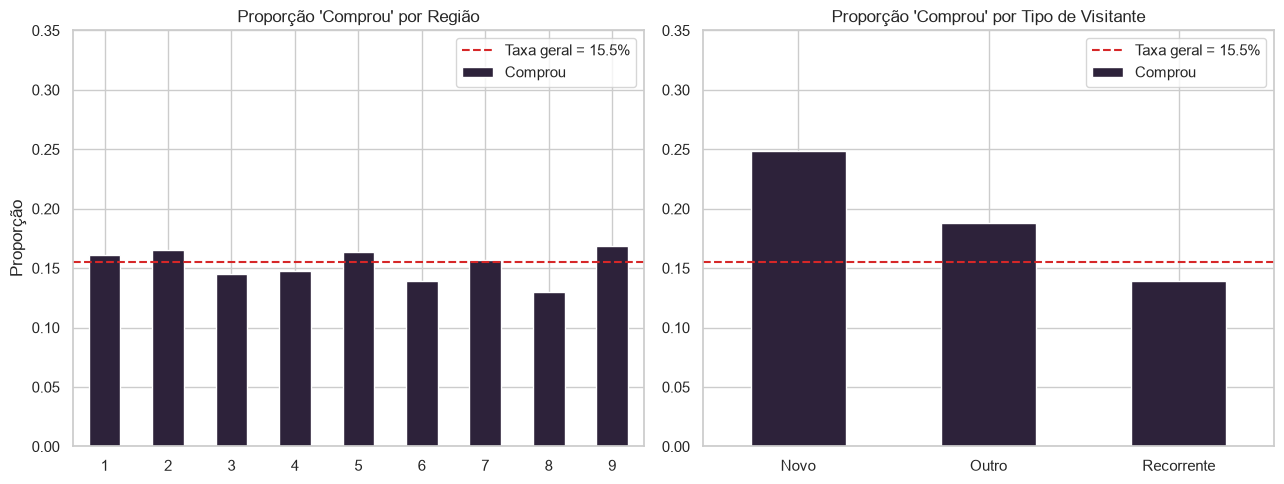

In [45]:
prop_por_regiao = pd.crosstab(df["regiao"], df["comprou"], normalize="index").round(3)
prop_por_regiao = prop_por_regiao.sort_index(key=lambda idx: idx.astype(int))
prop_por_visitante = pd.crosstab(df["tipo_visitante"], df["comprou"], normalize="index").round(3)
taxa_geral = (df["comprou"] == "Comprou").mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

prop_por_regiao["Comprou"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[0])
axes[0].set_title("Proporção 'Comprou' por Região")
axes[0].set_ylabel("Proporção")

prop_por_visitante["Comprou"].plot(kind="bar", color=COR_DESTAQUE, ax=axes[1])
axes[1].set_title("Proporção 'Comprou' por Tipo de Visitante")

for ax in axes:
    ax.axhline(taxa_geral, color=COR_ALERTA, linestyle="--", label=f"Taxa geral = {taxa_geral:.1%}")
    ax.set_ylim(0, 0.35)
    ax.tick_params(axis="x", rotation=0)
    ax.set_xlabel("")
    ax.legend()

plt.tight_layout()
plt.show()

**Pra discutir:** a taxa de compra varia entre regiões ou tipos de visitante?

*Resposta*: por **região**, a taxa é bem uniforme: vai de ~13% (região 8) a ~17% (região 9), todas em torno da taxa geral. É um bom sinal: não há indício de que a loja converta muito pior em alguma localidade. Por **tipo de visitante**, a diferença é grande: novos ~25% vs recorrentes ~14%. Um modelo treinado nesses dados aprenderia que "visitante novo" é um sinal positivo. Isso não é injusto em si, mas, se o modelo fosse usado para decidir **quem recebe desconto**, os recorrentes (a base fiel da loja) seriam sistematicamente preteridos. Vale lembrar que os grupos são muito desbalanceados (86% recorrentes), então a taxa dos novos é estimada com menos dados.

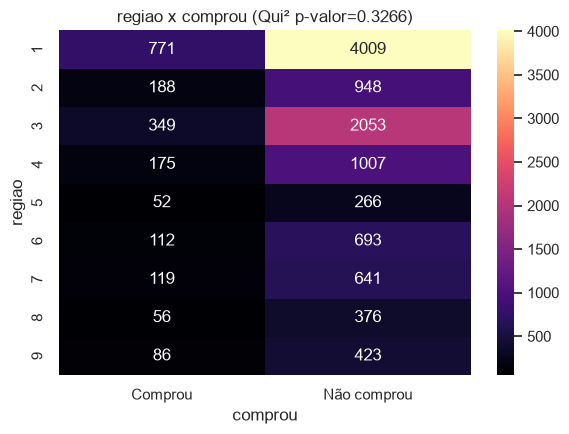

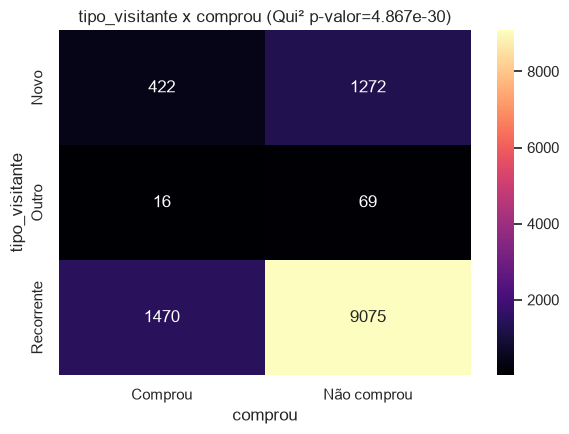

In [46]:
for atributo in ["regiao", "tipo_visitante"]:
    contingencia = pd.crosstab(df[atributo], df["comprou"])
    chi2, p_valor, gl, esperado = stats.chi2_contingency(contingencia)

    fig, ax = plt.subplots(figsize=(6, 4.5))
    sns.heatmap(contingencia, annot=True, fmt="d", cmap="magma", ax=ax)
    ax.set_title(f"{atributo} x comprou (Qui² p-valor={p_valor:.4g})")
    plt.tight_layout()
    plt.show()

**Pra discutir:** o Qui-Quadrado confirma associação?

*Resposta*: **não para região** (p ≈ 0,33: não rejeitamos a independência; a variação entre regiões é compatível com o acaso) e **sim para tipo de visitante** (p muito pequeno). Como na aula, o teste aponta **que** existe associação, não **por quê**: pode ser intenção de compra real, efeito da origem do tráfego (anúncios trazem visitantes novos) ou da sazonalidade. Separar essas causas exigiria uma análise controlando por mês e por `origem_trafego`.

#### Outliers bivariados

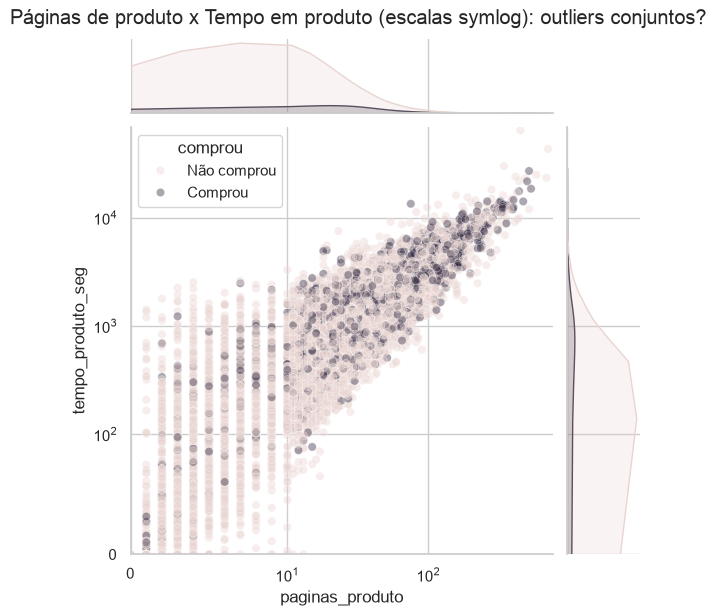

In [47]:
g = sns.jointplot(data=df, x="paginas_produto", y="tempo_produto_seg", hue="comprou",
                  palette=palette_classe, alpha=0.4, height=6)
g.ax_joint.set_yscale("symlog", linthresh=100)
g.ax_joint.set_xscale("symlog", linthresh=10)
g.ax_joint.set_xlim(left=0)
g.ax_joint.set_ylim(bottom=0)
g.figure.suptitle("Páginas de produto x Tempo em produto (escalas symlog): outliers conjuntos?", y=1.02)
plt.show()

In [48]:
# Tempo médio por página de produto: sessões com combinação incomum
tempo_por_pagina = (df["tempo_produto_seg"] / df["paginas_produto"]).where(df["paginas_produto"] > 0)
print(tempo_por_pagina.describe().round(1))
incomuns = df[tempo_por_pagina > 600]
print(f"\nSessões com mais de 10 min por página de produto: {len(incomuns)}")
print(incomuns[["paginas_produto", "tempo_produto_seg", "taxa_saida", "comprou"]])

count    12292.0
mean        37.8
std         44.8
min          0.0
25%         17.7
50%         29.0
75%         45.1
max       1411.0
dtype: float64

Sessões com mais de 10 min por página de produto: 11
       paginas_produto  tempo_produto_seg  taxa_saida      comprou
488                  4            2528.00    0.066667  Não comprou
536                  1            1411.00    0.100000  Não comprou
2176                 1             643.00    0.150000  Não comprou
3775                 2            1207.00    0.050000  Não comprou
3859                 1             612.00    0.100000  Não comprou
4581                 1            1364.00    0.100000  Não comprou
6329                 1            1195.80    0.000000  Não comprou
8421                 1             695.50    0.100000  Não comprou
8456                 3            2251.28    0.137427  Não comprou
9666                 3            1952.50    0.122222  Não comprou
11575                2            1787.50    0.150000  Não

**Pra discutir:** existe algum ponto que não parecia outlier nos univariados, mas que se destaca aqui?

*Resposta*: sim. Isoladamente, gastar ~20–40 min em páginas de produto é comum (está dentro do IQR de `tempo_produto_seg`), e ver 1–4 páginas também. Mas a **combinação** "pouquíssimas páginas **e** muito tempo" é rara: são as 11 sessões com mais de 10 min **por página** (ex.: 1 página e ~24 min). No gráfico, elas aparecem no canto superior esquerdo, afastadas da faixa diagonal. Nenhuma terminou em compra. Parecem abas abertas e esquecidas, e não leitura atenta. Elas não seriam detectadas olhando cada variável separadamente.

#### Análise Multivariada

##### Matriz de Correlação

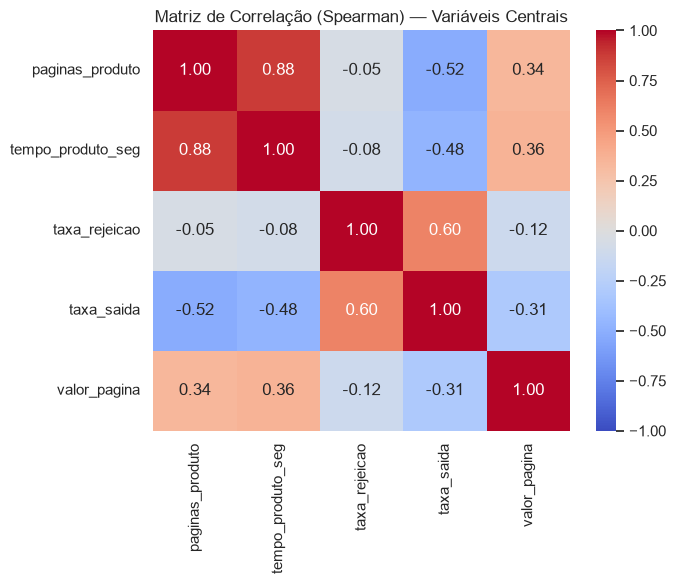

In [49]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[VARS_CORE].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matriz de Correlação (Spearman) — Variáveis Centrais")
plt.tight_layout()
plt.show()

**Como interpretar:**

*   |r| < 0.3 ~ fraca,
*   0.3 < |r| < 0.7 ~ moderada,
*  |r| > 0.7 ~ forte.

Entre as variáveis centrais, a única relação **forte** é `paginas_produto` x `tempo_produto_seg` (ρ ≈ 0,88): na prática, as duas medem o mesmo "engajamento com produtos", e usar ambas num modelo seria redundante. `taxa_rejeicao` x `taxa_saida` (≈ 0,60) e `taxa_saida` x `paginas_produto` (≈ −0,52) são **moderadas**. `valor_pagina` tem correlação fraca a moderada com as demais (|ρ| ≤ 0,36), ou seja, traz informação própria, coerente com ser a variável que mais separa as classes.

##### Correlograma

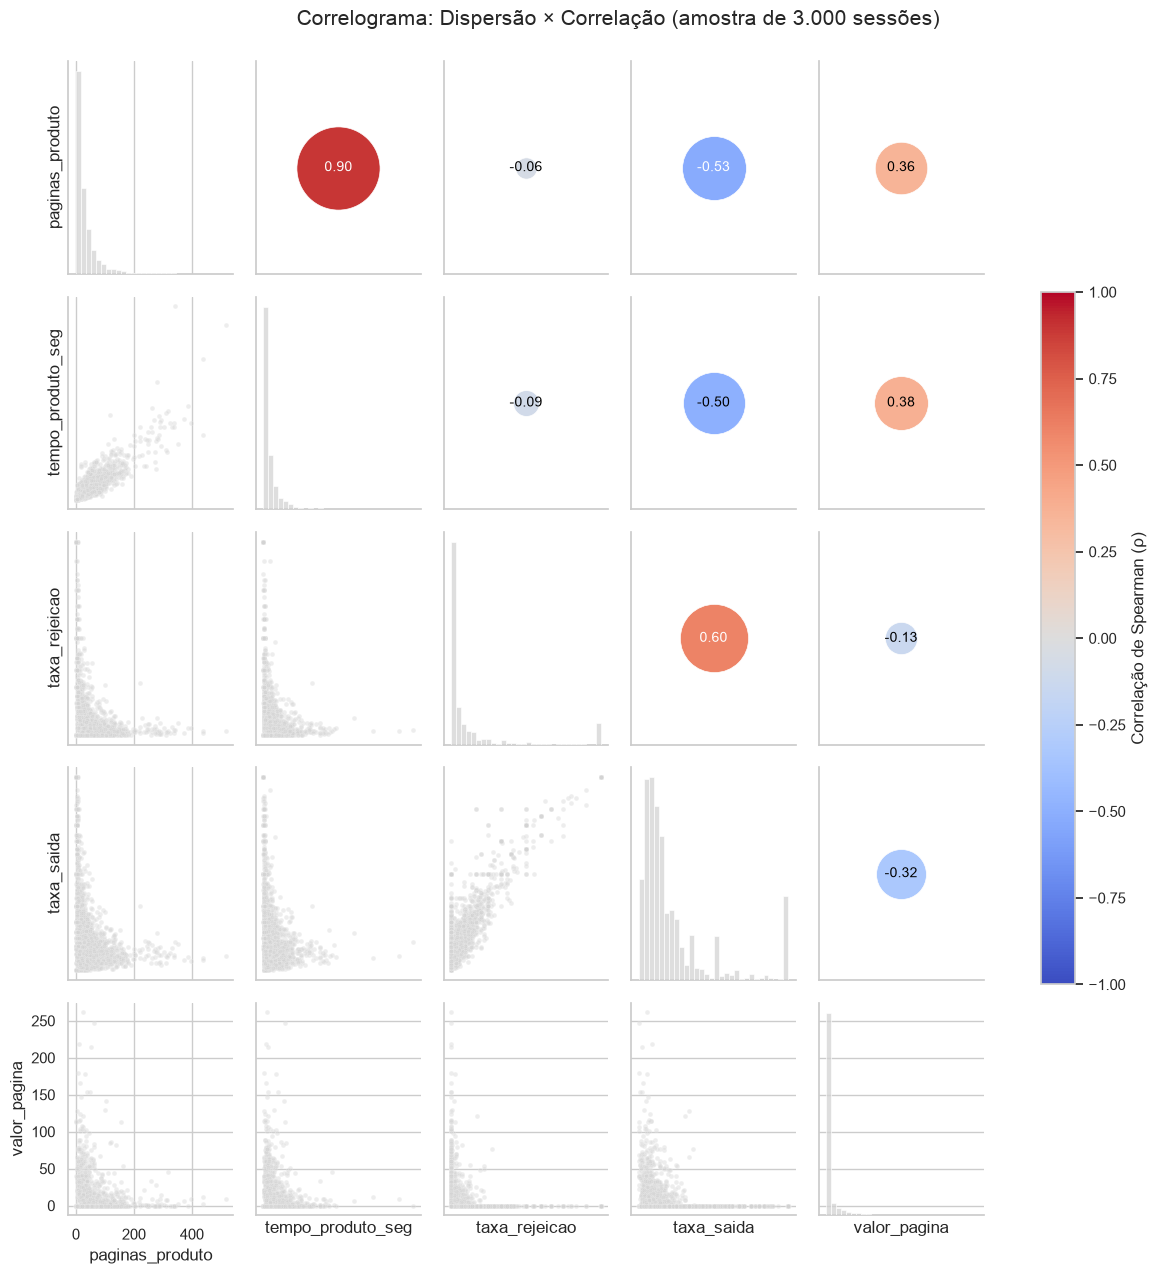

In [50]:
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize

def circulo_correlacao(x, y, **kwargs):
    r = stats.spearmanr(x, y).statistic
    ax = plt.gca()
    ax.scatter(
        [0.5], [0.5],
        s=abs(r) * 4000,          # tamanho proporcional à força da correlação
        c=[r], cmap="coolwarm", vmin=-1, vmax=1,
        transform=ax.transAxes, edgecolor="white", linewidth=0.5,
    )
    ax.annotate(f"{r:.2f}", xy=(0.5, 0.5), xycoords=ax.transAxes,
                ha="center", va="center", fontsize=10,
                color="white" if abs(r) > 0.5 else "black")
    ax.set_xticks([]); ax.set_yticks([])
    ax.grid(False)

amostra_corr = df[VARS_CORE].sample(3000, random_state=SEED)

g = sns.PairGrid(amostra_corr, diag_sharey=False)
g.map_lower(sns.scatterplot, color=COR_NEUTRA, alpha=0.4, s=12)
g.map_diag(sns.histplot, color=COR_NEUTRA, bins=30)
g.map_upper(circulo_correlacao)

sm = ScalarMappable(norm=Normalize(-1, 1), cmap="coolwarm")
sm.set_array([])
g.figure.colorbar(sm, ax=g.axes, shrink=0.6, label="Correlação de Spearman (ρ)")

g.figure.suptitle("Correlograma: Dispersão × Correlação (amostra de 3.000 sessões)", y=1.02, fontsize=15)
plt.show()

Usamos Spearman nos círculos (coerente com a não-normalidade) e uma amostra de 3.000 sessões. O correlograma resume a estrutura dos dados em **dois blocos**: um de **engajamento** (páginas e tempo de produto, positivamente ligados entre si e ao `valor_pagina`) e um de **abandono** (`taxa_rejeicao` e `taxa_saida`), negativamente ligado ao primeiro. A diagonal mostra de novo o padrão "muitos zeros + cauda longa" em todas as variáveis.

## Síntese

### Principais conclusões

1. **Ausências disfarçadas, não `NaN`.** O dataset parece completo, mas tem três tipos de ausência: tempo 0 em sessões com páginas vistas (o GA não mede o tempo da última página; MNAR, mantido com a flag `tempo_nao_medido`), 6 sessões sem nenhuma página (erro, removidas) e **janeiro e abril inteiros faltando** (limitação para qualquer conclusão sazonal).
2. **Distribuições de "muitos zeros + cauda longa".** Nenhuma variável é normal. ~78% das sessões têm `valor_pagina` = 0, e há sessões de até ~19h (abas esquecidas, outliers de domínio). Por isso usamos mediana, Spearman e testes não-paramétricos, e a regra do IQR se mostrou inadequada para variáveis com IQR = 0.
3. **O comportamento na sessão é o que mais separa quem compra.** `valor_pagina` tem efeito muito grande (rank-biserial ≈ 0,73; ~56% de compra quando é positivo vs ~4% quando é zero), seguido de `taxa_saida` (quem compra sai menos) e do engajamento com produtos. Variáveis técnicas (região, navegador, SO) quase não importam. Ressalva: `valor_pagina` pode embutir informação da própria compra (*data leakage*).
4. **Sazonalidade e tipo de visitante.** Novembro converte ~25% (Black Friday/pré-Natal) e fevereiro ~2%. Visitantes novos convertem mais que os recorrentes (~25% vs ~14%), um padrão a investigar antes de qualquer política de ofertas.
5. **Alvo desbalanceado e variáveis redundantes.** Só ~15,5% das sessões compram (razão 5,5:1), e cada contagem de páginas é quase redundante com a sua duração (ρ ≥ 0,88). As duas coisas devem ser consideradas numa modelagem futura.

### Declaração de Uso de IA

| Ferramenta | Para o que foi aplicada | O que foi aceito / modificado / rejeitado e por quê |
|---|---|---|
| Claude Code (Anthropic) | Adaptar a estrutura do notebook da aula (`arquivo-eda-original.ipynb`) ao dataset Online Shoppers Purchasing Intention: código das seções, escolha das variáveis, diagnóstico das ausências disfarçadas (tempo não medido, meses faltantes) e rascunho das respostas às perguntas de discussão. | *A preencher pelo aluno:* revisar cada decisão (ex.: manter as duplicatas, manter o tempo 0 com a flag `tempo_nao_medido`, remover as 6 sessões sem páginas, manter as sessões de várias horas) e registrar aqui o que foi aceito, modificado ou rejeitado, e por quê. |

## Exportando o dataset tratado

Exporta o `df` tratado para `data/clean/dataset.csv`, que é o arquivo lido pelo `app.py` (via `src/data_loader.py`).

In [51]:
df.to_csv(RAIZ / "data" / "clean" / "dataset.csv", index=False)
print(f"Exportado: {df.shape[0]} linhas x {df.shape[1]} colunas -> data/clean/dataset.csv")

Exportado: 12324 linhas x 20 colunas -> data/clean/dataset.csv
